# Myntra Seller Returns & Inventory Reconciliation System
## SQL Developer Colab

**Industry:** E-commerce  
**Role:** SQL Developer  
**Runtime:** Google Colab  
**Database:** SQLite  
**Main skills:** Relational database design, internal API consumption, SQL reporting, transaction integrity, workflow automation, and safe engineering practices

Myntra marketplace operations needs one reproducible control environment for customer returns, warehouse receipts, seller inventory adjustments, refund approvals, and product-quality exceptions. The runtime and internal API are prepared for you. Complete only the clearly marked SQL Developer workspaces.


## How to Use This Notebook

1. Choose **Runtime -> Run all**.
2. Wait until the setup prints **SETUP COMPLETE**.
3. Scroll to the large **SQL DEVELOPER WORK STARTS HERE** heading.
4. Edit only cells containing **SQL DEVELOPER WORKSPACE**.
5. Rerun each completed workspace until the validator shows **Overall status: Passed**.

All setup code is rerun-safe for a fresh Colab runtime. Mutable API activities reset their own practice records before use. Unanswered workspaces return **Needs Review** rather than a red runtime error.


# 1. RUN THIS SETUP ONCE - DO NOT EDIT

This single setup phase prepares the complete working environment: project folders, deterministic Dataset, temporary internal API, JSON extraction and validation, SQLite, constraints and indexes, system-managed operational tables, validation helpers, and the returns/inventory reconciliation engine.


## 1.1 Environment and Project Folder


In [ ]:
from __future__ import annotations

import copy
import hashlib
import json
import os
import random
import re
import shutil
import sqlite3
import subprocess
import sys
import threading
import time
from datetime import date, datetime, timedelta
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urlparse

import pandas as pd
import requests
from IPython.display import Markdown, display

try:
    from graphviz import Digraph
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "graphviz"])
    from graphviz import Digraph

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

BASE_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
PROJECT_ROOT = BASE_DIR / "myntra_returns_inventory_sql_developer"
if PROJECT_ROOT.exists():
    shutil.rmtree(PROJECT_ROOT)
for folder in ["data/raw", "data/processed", "database", "logs", "reports"]:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Environment ready")
print(f"Project runtime folder: {PROJECT_ROOT}")
print("Runtime: Google Colab compatible | Database: SQLite | Role: SQL Developer")


Environment ready
Project runtime folder: /content/myntra_returns_inventory_sql_developer
Runtime: Google Colab compatible | Database: SQLite | Role: SQL Developer


## 1.2 Dataset


In [ ]:
SEED = 20260810
REVIEW_DATE = date(2026, 8, 3)
DATA_START = date(2026, 7, 1)
CITIES = ['Bengaluru', 'Mumbai', 'Delhi', 'Hyderabad', 'Chennai', 'Pune', 'Kolkata', 'Ahmedabad']
SELLER_WORDS_A = ['Aster', 'Urban', 'Nova', 'Indigo', 'Velvet', 'Aura', 'Cedar', 'Loom', 'Mint', 'Coral', 'Peak', 'Nexa']
SELLER_WORDS_B = ['Fashion', 'Styles', 'Collective', 'Retail', 'Studio', 'Trends', 'Wardrobe', 'Apparel']
CATEGORIES = ['Women Ethnic', 'Men Casual', 'Footwear', 'Beauty', 'Accessories', 'Kids']
BRANDS = ['Aarika', 'Northlane', 'Viora', 'Kite & Loom', 'Mirae', 'Zestique', 'Threadline', 'Cobalt', 'Nivara', 'Fable']
REASONS = ['SIZE_FIT', 'DAMAGED', 'QUALITY', 'WRONG_ITEM', 'NOT_AS_EXPECTED']
WAREHOUSES = ['BLR-RC1', 'MUM-RC1', 'DEL-RC1', 'HYD-RC1']

def generate_dataset(seed=SEED):
    rng = random.Random(seed)
    # Sellers: exact 60
    sellers=[]
    for i in range(1,61):
        sellers.append({
            "seller_id":f"SEL{i:03d}",
            "seller_name":f"{rng.choice(SELLER_WORDS_A)} {rng.choice(SELLER_WORDS_B)} {i:02d}",
            "city":CITIES[(i-1)%len(CITIES)],
            "seller_tier":["GOLD","SILVER","BRONZE"][i%3],
            "status":"WATCHLIST" if i in {7,19,31,43,55} else ("SUSPENDED" if i==60 else "ACTIVE"),
            "onboarding_date":(date(2023,1,1)+timedelta(days=rng.randint(0,850))).isoformat(),
        })
    # Products: 5 per seller = 300
    products=[]
    pnum=1
    category_price_ranges={
        "Women Ethnic":(699,3499),"Men Casual":(599,2999),"Footwear":(799,3999),
        "Beauty":(299,1999),"Accessories":(249,2499),"Kids":(399,2299)
    }
    for s in sellers:
        for j in range(5):
            cat=CATEGORIES[(int(s['seller_id'][-3:])+j)%len(CATEGORIES)]
            lo,hi=category_price_ranges[cat]
            price=round(rng.randrange(lo//50, hi//50+1)*50 + 49,2)
            products.append({
                "product_id":f"PRD{pnum:04d}",
                "seller_id":s["seller_id"],
                "sku":f"MYN-{s['seller_id'][-3:]}-{j+1:02d}",
                "product_name":f"{rng.choice(BRANDS)} {cat} Item {pnum:03d}",
                "category":cat,
                "brand":rng.choice(BRANDS),
                "unit_price":price,
                "product_status":"INACTIVE" if pnum%97==0 else "ACTIVE",
            })
            pnum+=1
    product_by_id={p['product_id']:p for p in products}

    # Orders: 1500
    orders=[]; order_items=[]
    for i in range(1,1501):
        order_date=DATA_START+timedelta(days=rng.randint(0,24))
        status=rng.choices(["DELIVERED","CANCELLED","IN_TRANSIT"],[0.94,0.04,0.02])[0]
        delivered_date=(order_date+timedelta(days=rng.randint(2,5))).isoformat() if status=="DELIVERED" else None
        order_id=f"ORD{i:06d}"
        item_count=rng.choices([1,2,3],[0.60,0.31,0.09])[0]
        chosen=rng.sample(products,item_count)
        total=0.0
        rows=[]
        for p in chosen:
            qty=1 if rng.random()<0.88 else 2
            gross=p['unit_price']*qty
            discount=round(gross*rng.choice([0,0.05,0.10,0.15,0.20,0.25]),2)
            net=round(gross-discount,2)
            total+=net
            rows.append({
                "order_id":order_id,"product_id":p['product_id'],"quantity":qty,
                "unit_price":p['unit_price'],"discount_amount":discount,"net_amount":net
            })
        orders.append({
            "order_id":order_id,"order_date":order_date.isoformat(),"delivered_date":delivered_date,
            "customer_city":rng.choice(CITIES),"order_status":status,"order_total":round(total,2)
        })
        order_items.extend(rows)

    order_by_id={o['order_id']:o for o in orders}
    eligible=[]
    for oi in order_items:
        o=order_by_id[oi['order_id']]
        if o['order_status']=='DELIVERED':
            p=product_by_id[oi['product_id']]
            seller_num=int(p['seller_id'][-3:])
            risk=1.0 + (seller_num%10)*0.06 + {"Footwear":0.35,"Women Ethnic":0.22,"Men Casual":0.14,"Beauty":0.10,"Accessories":0.08,"Kids":0.18}[p['category']]
            eligible.append((oi,risk))
    # weighted sample without replacement 420
    pool=list(eligible); selected=[]
    for _ in range(420):
        total=sum(w for _,w in pool)
        x=rng.random()*total; acc=0
        for idx,(row,w) in enumerate(pool):
            acc+=w
            if acc>=x:
                selected.append(row); pool.pop(idx); break
    returns=[]
    for idx,oi in enumerate(selected,1):
        o=order_by_id[oi['order_id']]; p=product_by_id[oi['product_id']]
        delivered=date.fromisoformat(o['delivered_date'])
        request=delivered+timedelta(days=rng.randint(1,6))
        if request>date(2026,7,31): request=date(2026,7,31)
        reason=rng.choices(REASONS,[0.36,0.15,0.20,0.09,0.20])[0]
        return_qty=1 if oi['quantity']==1 else rng.choice([1,2])
        unit_net=oi['net_amount']/oi['quantity']
        expected_refund=round(unit_net*return_qty,2)
        # stage/status; ensure many RECEIVED and SIZE_FIT for API filter
        if idx<=12:
            reason="SIZE_FIT"; status="RECEIVED"
        else:
            status=rng.choices(["REQUESTED","PICKED_UP","RECEIVED","QC_COMPLETED","CLOSED","REJECTED"],[0.08,0.14,0.20,0.23,0.30,0.05])[0]
        pickup=None
        if status not in {"REQUESTED","REJECTED"}:
            pickup=(request+timedelta(days=rng.randint(1,3))).isoformat()
        returns.append({
            "return_id":f"RET{idx:05d}","order_id":oi['order_id'],"product_id":oi['product_id'],
            "request_date":request.isoformat(),"pickup_date":pickup,"return_qty":return_qty,
            "return_reason":reason,"return_status":status,"expected_refund":expected_refund
        })

    # Warehouse receipts for staged returns, controlled missing/late/quantity anomalies
    warehouse_receipts=[]
    rec_num=1
    for idx,r in enumerate(returns,1):
        if r['return_status'] not in {"RECEIVED","QC_COMPLETED","CLOSED"}: continue
        # Missing receipt anomalies: every 17th eligible
        if idx%17==0: continue
        pickup=date.fromisoformat(r['pickup_date'])
        delay=rng.randint(1,3)
        if idx%19==0: delay=6  # late
        receipt_date=pickup+timedelta(days=delay)
        # quantity mismatch on every 23rd
        received_qty=r['return_qty'] + (1 if idx%23==0 else 0)
        reason=r['return_reason']
        if reason in {"DAMAGED","QUALITY","WRONG_ITEM"}:
            qc=rng.choices(["QC_FAILED","QC_PASSED","QC_PENDING"],[0.55,0.30,0.15])[0]
        else:
            qc=rng.choices(["QC_PASSED","QC_FAILED","QC_PENDING"],[0.78,0.12,0.10])[0]
        if idx%29==0: qc="QC_FAILED"
        condition = ("SELLABLE" if qc=="QC_PASSED" else ("DEFECTIVE" if reason in {"DAMAGED","QUALITY"} else "WRONG_ITEM" if reason=="WRONG_ITEM" else "DAMAGED"))
        warehouse_receipts.append({
            "receipt_id":f"WRC{rec_num:05d}","return_id":r['return_id'],"product_id":r['product_id'],
            "receipt_reference":f"RCPT-2026-{rec_num:05d}","warehouse_code":WAREHOUSES[(rec_num-1)%4],
            "receipt_date":receipt_date.isoformat(),"received_qty":received_qty,"qc_status":qc,"condition_grade":condition
        })
        rec_num+=1

    # Refund approvals, with missing/pending/mismatch/duplicate references
    refund_approvals=[]; ref_num=1
    for idx,r in enumerate(returns,1):
        if r['return_status'] not in {"QC_COMPLETED","CLOSED","REJECTED"}: continue
        if r['return_status']!='REJECTED' and idx%13==0:  # missing refund
            continue
        if r['return_status']=='REJECTED':
            refund_status='REJECTED'; approved=0.0
        else:
            refund_status=rng.choices(["COMPLETED","APPROVED","PENDING"],[0.72,0.16,0.12])[0]
            approved=r['expected_refund']
            if idx%21==0:
                approved=round(max(0, approved-rng.choice([50,75,100])),2)
        base=date.fromisoformat(r['request_date'])+timedelta(days=rng.randint(3,9))
        payment_ref=f"RFD-PAY-{ref_num:05d}" if refund_status in {"COMPLETED","APPROVED"} else None
        # duplicate reference anomaly in pairs
        if idx in {44,88,132,176,220,264} and refund_status in {"COMPLETED","APPROVED"} and refund_approvals:
            payment_ref=refund_approvals[-1]['payment_reference'] or f"RFD-PAY-DUP-{idx:03d}"
            if refund_approvals[-1]['payment_reference'] is None:
                refund_approvals[-1]['payment_reference']=payment_ref
        refund_approvals.append({
            "refund_approval_id":f"RFA{ref_num:05d}","return_id":r['return_id'],"approval_date":base.isoformat(),
            "approved_amount":round(approved,2),"refund_status":refund_status,"payment_reference":payment_ref
        })
        ref_num+=1

    return {
        'sellers':sellers,'products':products,'orders':orders,'order_items':order_items,'returns':returns,
        'warehouse_receipts':warehouse_receipts,'refund_approvals':refund_approvals
    }


dataset = generate_dataset(SEED)
dataset_counts = pd.DataFrame(
    [(name, len(rows)) for name, rows in dataset.items()],
    columns=["Dataset resource", "row_count"]
)
display(dataset_counts)
print("Dataset generated with fixed seed:", SEED)
print("Review date:", REVIEW_DATE.isoformat())


,Dataset resource,row_count
0,sellers,60
1,products,300
2,orders,1500
3,order_items,2229
4,returns,420
5,warehouse_receipts,293
6,refund_approvals,208


Dataset generated with fixed seed: 20260810
Review date: 2026-08-03


## 1.3 Temporary Internal API


In [ ]:
# Stop an earlier server if this setup section is rerun in the same runtime.
if "api_server" in globals():
    try:
        api_server.shutdown()
        api_server.server_close()
    except Exception:
        pass

API_RESOURCES = ["sellers", "products", "orders", "order_items", "returns", "warehouse_receipts", "refund_approvals"]
RESOURCE_ID_FIELDS = {
    "sellers": "seller_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": None,
    "returns": "return_id",
    "warehouse_receipts": "receipt_id",
    "refund_approvals": "refund_approval_id",
}
RETURN_REQUIRED_FIELDS = {
    "return_id", "order_id", "product_id", "request_date", "pickup_date", "return_qty",
    "return_reason", "return_status", "expected_refund"
}
RETURN_PATCH_FIELDS = RETURN_REQUIRED_FIELDS - {"return_id"}
api_data = {name: copy.deepcopy(dataset[name]) for name in API_RESOURCES}

class InternalAPIHandler(BaseHTTPRequestHandler):
    server_version = "MarketplaceReturnsInternalAPI/1.0"

    def log_message(self, format, *args):
        return

    def _send_json(self, payload, status=200):
        body = json.dumps(payload, default=str).encode("utf-8")
        self.send_response(status)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        self.wfile.write(body)

    def _read_json(self):
        length = int(self.headers.get("Content-Length", "0") or 0)
        if length <= 0:
            return {}
        try:
            return json.loads(self.rfile.read(length).decode("utf-8"))
        except Exception:
            return None

    def _parts(self):
        parsed = urlparse(self.path)
        return parsed, [p for p in parsed.path.split("/") if p]

    def do_GET(self):
        parsed, parts = self._parts()
        if not parts or parts[0] not in api_data:
            return self._send_json({"error": "resource not found"}, 404)
        resource = parts[0]
        if len(parts) == 2:
            id_field = RESOURCE_ID_FIELDS.get(resource)
            if not id_field:
                return self._send_json({"error": "item lookup not supported"}, 404)
            record = next((r for r in api_data[resource] if str(r.get(id_field)) == parts[1]), None)
            return self._send_json(record if record else {"error": "record not found"}, 200 if record else 404)
        if len(parts) > 1:
            return self._send_json({"error": "resource not found"}, 404)
        params = {k: v[-1] for k, v in parse_qs(parsed.query).items()}
        try:
            limit = max(1, min(int(params.pop("limit", 200)), 500))
            offset = max(0, int(params.pop("offset", 0)))
        except ValueError:
            return self._send_json({"error": "limit and offset must be integers"}, 400)
        rows = api_data[resource]
        for key, value in params.items():
            if rows and key not in rows[0]:
                return self._send_json({"error": f"unsupported filter: {key}"}, 400)
            rows = [r for r in rows if str(r.get(key)) == value]
        total = len(rows)
        batch = rows[offset:offset + limit]
        return self._send_json({"data": batch, "meta": {"total": total, "limit": limit, "offset": offset}}, 200)

    def do_POST(self):
        parsed, parts = self._parts()
        if parts != ["returns"]:
            return self._send_json({"error": "method not supported"}, 404)
        payload = self._read_json()
        if not isinstance(payload, dict) or set(payload) != RETURN_REQUIRED_FIELDS:
            return self._send_json({"error": "complete return payload required"}, 400)
        if next((r for r in api_data["returns"] if r["return_id"] == payload["return_id"]), None):
            return self._send_json({"error": "return_id already exists"}, 409)
        api_data["returns"].append(copy.deepcopy(payload))
        return self._send_json(payload, 201)

    def do_PUT(self):
        parsed, parts = self._parts()
        if len(parts) != 2 or parts[0] != "returns":
            return self._send_json({"error": "resource not found"}, 404)
        payload = self._read_json()
        if not isinstance(payload, dict) or set(payload) != RETURN_REQUIRED_FIELDS or payload.get("return_id") != parts[1]:
            return self._send_json({"error": "complete replacement payload with matching return_id required"}, 400)
        for i, row in enumerate(api_data["returns"]):
            if row["return_id"] == parts[1]:
                api_data["returns"][i] = copy.deepcopy(payload)
                return self._send_json(payload, 200)
        return self._send_json({"error": "record not found"}, 404)

    def do_PATCH(self):
        parsed, parts = self._parts()
        if len(parts) != 2 or parts[0] != "returns":
            return self._send_json({"error": "resource not found"}, 404)
        payload = self._read_json()
        if not isinstance(payload, dict) or not payload or any(k not in RETURN_PATCH_FIELDS for k in payload):
            return self._send_json({"error": "unsupported patch fields"}, 400)
        for row in api_data["returns"]:
            if row["return_id"] == parts[1]:
                row.update(copy.deepcopy(payload))
                return self._send_json(row, 200)
        return self._send_json({"error": "record not found"}, 404)

    def do_DELETE(self):
        parsed, parts = self._parts()
        if len(parts) != 2 or parts[0] != "returns":
            return self._send_json({"error": "resource not found"}, 404)
        for i, row in enumerate(api_data["returns"]):
            if row["return_id"] == parts[1]:
                deleted = api_data["returns"].pop(i)
                return self._send_json(deleted, 200)
        return self._send_json({"error": "record not found"}, 404)

api_server = ThreadingHTTPServer(("127.0.0.1", 0), InternalAPIHandler)
api_thread = threading.Thread(target=api_server.serve_forever, daemon=True)
api_thread.start()
API_BASE_URL = f"http://127.0.0.1:{api_server.server_address[1]}"

# Quick health check using a read endpoint.
health = requests.get(f"{API_BASE_URL}/sellers", params={"limit": 1}, timeout=10)
health.raise_for_status()
print("Temporary internal API ready")
print("Base URL:", API_BASE_URL)
print("Health check status:", health.status_code)


Temporary internal API ready
Base URL: http://127.0.0.1:46207
Health check status: 200


In [ ]:
api_documentation = pd.DataFrame([
    ["GET", "/sellers", "Read seller master records", "200"],
    ["GET", "/products", "Read product and seller ownership records", "200"],
    ["GET", "/orders", "Read order headers", "200"],
    ["GET", "/order_items", "Read item-level order records", "200"],
    ["GET", "/returns", "Read returns; supports filters and pagination", "200"],
    ["GET", "/returns/{id}", "Read one return", "200 / 404"],
    ["POST", "/returns", "Create one return", "201 / 400 / 409"],
    ["PUT", "/returns/{id}", "Replace a complete return", "200 / 400 / 404"],
    ["PATCH", "/returns/{id}", "Update selected return fields", "200 / 400 / 404"],
    ["DELETE", "/returns/{id}", "Delete one return", "200 / 404"],
    ["GET", "/warehouse_receipts", "Read warehouse receipt and QC records", "200"],
    ["GET", "/refund_approvals", "Read refund approval records", "200"],
], columns=["method", "endpoint", "purpose", "expected_status"])
display(api_documentation)


,method,endpoint,purpose,expected_status
0,GET,/sellers,Read seller master records,200
1,GET,/products,Read product and seller ownership records,200
2,GET,/orders,Read order headers,200
3,GET,/order_items,Read item-level order records,200
4,GET,/returns,Read returns; supports filters and pagination,200
5,GET,/returns/{id},Read one return,200 / 404
6,POST,/returns,Create one return,201 / 400 / 409
7,PUT,/returns/{id},Replace a complete return,200 / 400 / 404
8,PATCH,/returns/{id},Update selected return fields,200 / 400 / 404
9,DELETE,/returns/{id},Delete one return,200 / 404


## 1.4 API Extraction and Dataset Validation


In [ ]:
def fetch_all(resource: str, page_size: int = 250):
    started_at = datetime.now()
    records = []
    offset = 0
    error_message = None
    status = "SUCCESS"
    try:
        while True:
            response = requests.get(f"{API_BASE_URL}/{resource}", params={"limit": page_size, "offset": offset}, timeout=10)
            response.raise_for_status()
            payload = response.json()
            batch = payload["data"]
            records.extend(batch)
            offset += len(batch)
            if not batch or offset >= payload["meta"]["total"]:
                break
    except Exception as exc:
        status = "FAILED"
        error_message = str(exc)
        raise
    finally:
        ended_at = datetime.now()
    raw_path = PROJECT_ROOT / "data" / "raw" / f"{resource}.json"
    raw_path.write_text(json.dumps(records, indent=2), encoding="utf-8")
    return records, {
        "endpoint": f"/{resource}",
        "started_at": started_at.isoformat(sep=" ", timespec="seconds"),
        "ended_at": ended_at.isoformat(sep=" ", timespec="seconds"),
        "rows_received": len(records),
        "rows_loaded": len(records),
        "status": status,
        "error_message": error_message,
    }

frames = {}
ingestion_metadata = []
for resource in API_RESOURCES:
    records, meta = fetch_all(resource)
    frames[resource] = pd.DataFrame(records)
    frames[resource].to_json(PROJECT_ROOT / "data" / "processed" / f"{resource}.json", orient="records", indent=2)
    ingestion_metadata.append(meta)

ingestion_preview = pd.DataFrame(ingestion_metadata)[["endpoint","rows_received","rows_loaded","status"]]
display(ingestion_preview)
print("API extraction complete for", len(API_RESOURCES), "resources")


,endpoint,rows_received,rows_loaded,status
0,/sellers,60,60,SUCCESS
1,/products,300,300,SUCCESS
2,/orders,1500,1500,SUCCESS
3,/order_items,2229,2229,SUCCESS
4,/returns,420,420,SUCCESS
5,/warehouse_receipts,293,293,SUCCESS
6,/refund_approvals,208,208,SUCCESS


API extraction complete for 7 resources


In [ ]:
DATA_CONTRACTS = {'sellers': ['seller_id', 'seller_name', 'city', 'seller_tier', 'status', 'onboarding_date'], 'products': ['product_id', 'seller_id', 'sku', 'product_name', 'category', 'brand', 'unit_price', 'product_status'], 'orders': ['order_id', 'order_date', 'delivered_date', 'customer_city', 'order_status', 'order_total'], 'order_items': ['order_id', 'product_id', 'quantity', 'unit_price', 'discount_amount', 'net_amount'], 'returns': ['return_id', 'order_id', 'product_id', 'request_date', 'pickup_date', 'return_qty', 'return_reason', 'return_status', 'expected_refund'], 'warehouse_receipts': ['receipt_id', 'return_id', 'product_id', 'receipt_reference', 'warehouse_code', 'receipt_date', 'received_qty', 'qc_status', 'condition_grade'], 'refund_approvals': ['refund_approval_id', 'return_id', 'approval_date', 'approved_amount', 'refund_status', 'payment_reference']}
PRIMARY_KEYS = {'sellers': ['seller_id'], 'products': ['product_id'], 'orders': ['order_id'], 'order_items': ['order_id', 'product_id'], 'returns': ['return_id'], 'warehouse_receipts': ['receipt_id'], 'refund_approvals': ['refund_approval_id']}
quality_results = []
for resource in API_RESOURCES:
    df = frames[resource]
    expected_cols = DATA_CONTRACTS[resource]
    columns_ok = list(df.columns) == expected_cols
    missing_pk = int(df[PRIMARY_KEYS[resource]].isna().any(axis=1).sum())
    duplicate_pk = int(df.duplicated(PRIMARY_KEYS[resource]).sum())
    quality_results.append({
        "resource": resource,
        "columns_ok": columns_ok,
        "missing_primary_keys": missing_pk,
        "duplicate_primary_keys": duplicate_pk,
        "status": "Passed" if columns_ok and missing_pk == 0 and duplicate_pk == 0 else "Needs Review"
    })
quality_df = pd.DataFrame(quality_results)
display(quality_df)
assert (quality_df["status"] == "Passed").all(), "Dataset contract validation failed"
print("Dataset and JSON structural validation: Passed")


,resource,columns_ok,missing_primary_keys,duplicate_primary_keys,status
0,sellers,True,0,0,Passed
1,products,True,0,0,Passed
2,orders,True,0,0,Passed
3,order_items,True,0,0,Passed
4,returns,True,0,0,Passed
5,warehouse_receipts,True,0,0,Passed
6,refund_approvals,True,0,0,Passed


Dataset and JSON structural validation: Passed


## 1.5 SQLite Database Creation


In [ ]:
DB_PATH = PROJECT_ROOT / "database" / "myntra_returns_inventory.db"
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")
DDL = "\nPRAGMA foreign_keys = ON;\nCREATE TABLE sellers (\n seller_id TEXT PRIMARY KEY NOT NULL,\n seller_name TEXT NOT NULL,\n city TEXT NOT NULL,\n seller_tier TEXT NOT NULL CHECK (seller_tier IN ('GOLD','SILVER','BRONZE')),\n status TEXT NOT NULL CHECK (status IN ('ACTIVE','WATCHLIST','SUSPENDED')),\n onboarding_date TEXT NOT NULL\n);\nCREATE TABLE products (\n product_id TEXT PRIMARY KEY NOT NULL,\n seller_id TEXT NOT NULL,\n sku TEXT NOT NULL UNIQUE,\n product_name TEXT NOT NULL,\n category TEXT NOT NULL,\n brand TEXT NOT NULL,\n unit_price REAL NOT NULL CHECK (unit_price > 0),\n product_status TEXT NOT NULL CHECK (product_status IN ('ACTIVE','INACTIVE')),\n FOREIGN KEY (seller_id) REFERENCES sellers(seller_id)\n);\nCREATE TABLE orders (\n order_id TEXT PRIMARY KEY NOT NULL,\n order_date TEXT NOT NULL,\n delivered_date TEXT,\n customer_city TEXT NOT NULL,\n order_status TEXT NOT NULL CHECK (order_status IN ('DELIVERED','CANCELLED','IN_TRANSIT')),\n order_total REAL NOT NULL CHECK (order_total >= 0)\n);\nCREATE TABLE order_items (\n order_id TEXT NOT NULL,\n product_id TEXT NOT NULL,\n quantity INTEGER NOT NULL CHECK (quantity > 0),\n unit_price REAL NOT NULL CHECK (unit_price > 0),\n discount_amount REAL NOT NULL CHECK (discount_amount >= 0),\n net_amount REAL NOT NULL CHECK (net_amount >= 0),\n PRIMARY KEY (order_id, product_id),\n FOREIGN KEY (order_id) REFERENCES orders(order_id),\n FOREIGN KEY (product_id) REFERENCES products(product_id)\n);\nCREATE TABLE returns (\n return_id TEXT PRIMARY KEY NOT NULL,\n order_id TEXT NOT NULL,\n product_id TEXT NOT NULL,\n request_date TEXT NOT NULL,\n pickup_date TEXT,\n return_qty INTEGER NOT NULL CHECK (return_qty > 0),\n return_reason TEXT NOT NULL CHECK (return_reason IN ('SIZE_FIT','DAMAGED','QUALITY','WRONG_ITEM','NOT_AS_EXPECTED')),\n return_status TEXT NOT NULL CHECK (return_status IN ('REQUESTED','PICKED_UP','RECEIVED','QC_COMPLETED','CLOSED','REJECTED')),\n expected_refund REAL NOT NULL CHECK (expected_refund >= 0),\n FOREIGN KEY (order_id) REFERENCES orders(order_id),\n FOREIGN KEY (product_id) REFERENCES products(product_id)\n);\nCREATE TABLE warehouse_receipts (\n receipt_id TEXT PRIMARY KEY NOT NULL,\n return_id TEXT NOT NULL,\n product_id TEXT NOT NULL,\n receipt_reference TEXT NOT NULL UNIQUE,\n warehouse_code TEXT NOT NULL,\n receipt_date TEXT NOT NULL,\n received_qty INTEGER NOT NULL CHECK (received_qty > 0),\n qc_status TEXT NOT NULL CHECK (qc_status IN ('QC_PASSED','QC_FAILED','QC_PENDING')),\n condition_grade TEXT NOT NULL CHECK (condition_grade IN ('SELLABLE','DAMAGED','DEFECTIVE','WRONG_ITEM')),\n FOREIGN KEY (return_id) REFERENCES returns(return_id),\n FOREIGN KEY (product_id) REFERENCES products(product_id)\n);\nCREATE TABLE refund_approvals (\n refund_approval_id TEXT PRIMARY KEY NOT NULL,\n return_id TEXT NOT NULL,\n approval_date TEXT NOT NULL,\n approved_amount REAL NOT NULL CHECK (approved_amount >= 0),\n refund_status TEXT NOT NULL CHECK (refund_status IN ('PENDING','APPROVED','COMPLETED','REJECTED')),\n payment_reference TEXT,\n FOREIGN KEY (return_id) REFERENCES returns(return_id)\n);\nCREATE TABLE inventory_adjustment_ledger (\n adjustment_id TEXT PRIMARY KEY NOT NULL,\n seller_id TEXT NOT NULL,\n product_id TEXT NOT NULL,\n return_id TEXT,\n adjustment_timestamp TEXT NOT NULL,\n adjustment_type TEXT NOT NULL CHECK (adjustment_type IN ('RESTOCK','MANUAL_CORRECTION','QUARANTINE_RELEASE')),\n quantity_change INTEGER NOT NULL CHECK (quantity_change <> 0),\n approval_status TEXT NOT NULL CHECK (approval_status IN ('PENDING','APPROVED','SYSTEM')),\n reason TEXT NOT NULL,\n FOREIGN KEY (seller_id) REFERENCES sellers(seller_id),\n FOREIGN KEY (product_id) REFERENCES products(product_id),\n FOREIGN KEY (return_id) REFERENCES returns(return_id)\n);\nCREATE TABLE reconciliation_exceptions (\n exception_id INTEGER PRIMARY KEY AUTOINCREMENT,\n seller_id TEXT NOT NULL,\n return_id TEXT,\n entity_type TEXT NOT NULL,\n entity_id TEXT NOT NULL,\n exception_type TEXT NOT NULL,\n severity TEXT NOT NULL CHECK (severity IN ('LOW','MEDIUM','HIGH','CRITICAL')),\n expected_value REAL,\n actual_value REAL,\n detected_at TEXT NOT NULL,\n resolution_status TEXT NOT NULL CHECK (resolution_status IN ('OPEN','INVESTIGATING','CLOSED')),\n FOREIGN KEY (seller_id) REFERENCES sellers(seller_id),\n FOREIGN KEY (return_id) REFERENCES returns(return_id)\n);\nCREATE TABLE api_ingestion_runs (\n run_id INTEGER PRIMARY KEY AUTOINCREMENT,\n endpoint TEXT NOT NULL,\n started_at TEXT NOT NULL,\n ended_at TEXT NOT NULL,\n rows_received INTEGER NOT NULL CHECK (rows_received >= 0),\n rows_loaded INTEGER NOT NULL CHECK (rows_loaded >= 0),\n status TEXT NOT NULL CHECK (status IN ('SUCCESS','FAILED')),\n error_message TEXT\n);\nCREATE INDEX idx_products_seller_category ON products(seller_id, category);\nCREATE INDEX idx_orders_date_status ON orders(order_date, order_status);\nCREATE INDEX idx_order_items_product ON order_items(product_id);\nCREATE INDEX idx_returns_status_request ON returns(return_status, request_date);\nCREATE INDEX idx_returns_order_product ON returns(order_id, product_id);\nCREATE INDEX idx_receipts_return_date ON warehouse_receipts(return_id, receipt_date);\nCREATE INDEX idx_receipts_qc ON warehouse_receipts(qc_status, condition_grade);\nCREATE INDEX idx_refunds_return_status ON refund_approvals(return_id, refund_status);\nCREATE INDEX idx_refunds_payment_ref ON refund_approvals(payment_reference);\nCREATE INDEX idx_ledger_product_time ON inventory_adjustment_ledger(product_id, adjustment_timestamp);\nCREATE INDEX idx_exceptions_status_type ON reconciliation_exceptions(resolution_status, exception_type);\nCREATE INDEX idx_exceptions_seller ON reconciliation_exceptions(seller_id, severity);\n"
conn.executescript(DDL)

TABLE_COLUMNS = {'sellers': ['seller_id', 'seller_name', 'city', 'seller_tier', 'status', 'onboarding_date'], 'products': ['product_id', 'seller_id', 'sku', 'product_name', 'category', 'brand', 'unit_price', 'product_status'], 'orders': ['order_id', 'order_date', 'delivered_date', 'customer_city', 'order_status', 'order_total'], 'order_items': ['order_id', 'product_id', 'quantity', 'unit_price', 'discount_amount', 'net_amount'], 'returns': ['return_id', 'order_id', 'product_id', 'request_date', 'pickup_date', 'return_qty', 'return_reason', 'return_status', 'expected_refund'], 'warehouse_receipts': ['receipt_id', 'return_id', 'product_id', 'receipt_reference', 'warehouse_code', 'receipt_date', 'received_qty', 'qc_status', 'condition_grade'], 'refund_approvals': ['refund_approval_id', 'return_id', 'approval_date', 'approved_amount', 'refund_status', 'payment_reference']}
for table, cols in TABLE_COLUMNS.items():
    records = frames[table].to_dict("records")
    if records:
        placeholders = ",".join(["?"] * len(cols))
        sql = f"INSERT INTO {table} ({','.join(cols)}) VALUES ({placeholders})"
        conn.executemany(sql, [[r.get(c) for c in cols] for r in records])

for meta in ingestion_metadata:
    conn.execute(
        "INSERT INTO api_ingestion_runs(endpoint,started_at,ended_at,rows_received,rows_loaded,status,error_message) VALUES (?,?,?,?,?,?,?)",
        (meta["endpoint"], meta["started_at"], meta["ended_at"], meta["rows_received"], meta["rows_loaded"], meta["status"], meta["error_message"])
    )

# System-managed restock ledger: QC-passed sellable receipt quantities become positive stock adjustments.
restock_rows = conn.execute("""
SELECT wr.receipt_id, r.return_id, p.seller_id, r.product_id, wr.receipt_date, wr.received_qty
FROM warehouse_receipts wr
JOIN returns r ON r.return_id = wr.return_id
JOIN products p ON p.product_id = r.product_id
WHERE wr.qc_status='QC_PASSED' AND wr.condition_grade='SELLABLE'
ORDER BY wr.receipt_id
""").fetchall()
for n, (receipt_id, return_id, seller_id, product_id, receipt_date, qty) in enumerate(restock_rows, 1):
    if n % 31 == 0:  # controlled missing-ledger anomaly for reconciliation practice
        continue
    conn.execute("""
    INSERT INTO inventory_adjustment_ledger(
        adjustment_id,seller_id,product_id,return_id,adjustment_timestamp,
        adjustment_type,quantity_change,approval_status,reason
    ) VALUES (?,?,?,?,?,?,?,?,?)
    """, (f"ADJ-SYS-{n:05d}", seller_id, product_id, return_id, receipt_date + " 18:00:00", "RESTOCK", qty, "SYSTEM", "QC-passed return restocked"))
conn.commit()

schema_tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name", conn)
index_count = conn.execute("SELECT COUNT(*) FROM sqlite_master WHERE type='index' AND sql IS NOT NULL").fetchone()[0]
foreign_keys_enabled = conn.execute("PRAGMA foreign_keys").fetchone()[0]
print("SQLite database created:", DB_PATH)
print("Foreign keys enabled:", bool(foreign_keys_enabled))
print("Practical indexes created:", index_count)
display(schema_tables)


SQLite database created: /content/myntra_returns_inventory_sql_developer/database/myntra_returns_inventory.db
Foreign keys enabled: True
Practical indexes created: 12


,name
0,api_ingestion_runs
1,inventory_adjustment_ledger
2,order_items
3,orders
4,products
5,reconciliation_exceptions
6,refund_approvals
7,returns
8,sellers
9,warehouse_receipts


## 1.6 SQL Developer Validation and Visualization Helpers


In [ ]:
# PREBUILT HELPERS - DO NOT EDIT
ACTIVITY_IDS = ["ER-1"] + [f"API-Q{i}" for i in range(1,6)] + [f"Q{i}" for i in range(1,14)] + ["T1","T2","AUTO-FLOW","AUTO-REPORT","AUTO-CRON","ENG-GIT","ENG-CHANGE"]
activity_state = {activity_id: "Needs Review" for activity_id in ACTIVITY_IDS}
REFERENCE_SIGNATURES = json.loads('{"Q1": {"columns": ["return_id", "seller_name", "product_name", "expected_refund", "return_status", "return_reason", "request_date"], "rows": 10, "digest": "e1277c292670a25d33811e56ae5d870aa3198ef0b60c708f4d62be60fc06d114", "first_row": {"return_id": "RET00409", "expected_refund": 5698.5, "return_status": "QC_COMPLETED"}, "key_fields": ["return_id", "expected_refund", "return_status"]}, "Q2": {"columns": ["seller_id", "seller_name", "return_count", "refund_exposure"], "rows": 47, "digest": "1ca8405588afe698f2be8136e2a9764033644faea622791541fe16ed84602293", "first_row": {"seller_id": "SEL028", "return_count": 10, "refund_exposure": 25971.0}, "key_fields": ["seller_id", "return_count", "refund_exposure"]}, "Q3": {"columns": ["return_id", "seller_name", "return_qty", "received_qty", "expected_refund", "approved_amount", "reconciliation_status"], "rows": 20, "digest": "cda2e3c16d2ca93718f636c11b2a17c8a332787cb183dd1630fd380ee00d86db", "first_row": {"return_id": "RET00142", "expected_refund": 5198.0, "reconciliation_status": "REFUND_MISSING"}, "key_fields": ["return_id", "expected_refund", "reconciliation_status"]}, "Q4": {"columns": ["return_id", "seller_id", "seller_name", "pickup_date", "return_status", "expected_refund"], "rows": 66, "digest": "f4585d9163b49a0b3c115d1d95750ec64991bc8951ebb6598a3f999de491d86c", "first_row": {"return_id": "RET00301", "pickup_date": "2026-07-08", "return_status": "PICKED_UP"}, "key_fields": ["return_id", "pickup_date", "return_status"]}, "Q5": {"columns": ["seller_id", "seller_name", "city"], "rows": 52, "digest": "976683d10b0abd08d933735053954977bd9878e5b968e6343f0a361187ba7ae6", "first_row": {"seller_id": "SEL002", "city": "Mumbai"}, "key_fields": ["seller_id", "city"]}, "Q6": {"columns": ["seller_id", "seller_name_upper", "city_code", "seller_age_days", "return_count", "open_exception_count", "return_value", "risk_band"], "rows": 15, "digest": "24bf2039f4fbeeb1ea694d51cb934e89b3ed5b516c1a29911d0fb46dca59bf11", "first_row": {"seller_id": "SEL052", "open_exception_count": 12, "risk_band": "HIGH"}, "key_fields": ["seller_id", "open_exception_count", "risk_band"]}, "Q7": {"columns": ["seller_id", "seller_name", "return_rate_pct"], "rows": 30, "digest": "b90bcfcc5a502230349ae0071e999a4bf4381af8cb97f124889fe40002cd12fa", "first_row": {"seller_id": "SEL059", "return_rate_pct": 34.62}, "key_fields": ["seller_id", "return_rate_pct"]}, "Q8": {"columns": ["seller_id", "product_id", "expected_restock_qty", "actual_restock_qty", "qty_gap"], "rows": 5, "digest": "c513f3506f73d6e08527bcdd57cf71d21aaac9a5d66daadbcf97f80333a8ef7f", "first_row": {"seller_id": "SEL016", "product_id": "PRD0080", "qty_gap": 2}, "key_fields": ["seller_id", "product_id", "qty_gap"]}, "Q9": {"columns": ["city", "seller_id", "seller_name", "return_rate_pct", "city_return_rank"], "rows": 60, "digest": "1498e614e5786dc3982260a7a3544f7f8e6ff910bdb3483f5ac14765bc68a6e7", "first_row": {"city": "Ahmedabad", "seller_id": "SEL056", "city_return_rank": 1}, "key_fields": ["city", "seller_id", "city_return_rank"]}, "Q10": {"columns": ["return_date", "daily_refund_exposure", "running_refund_exposure", "seven_day_moving_avg"], "rows": 31, "digest": "c194f4437e5bb24cbf7b7f1debe9cb52d8febd564fc1777a94f8dd8bcbf14273", "first_row": {"return_date": "2026-07-01", "daily_refund_exposure": 0.0, "running_refund_exposure": 0.0}, "key_fields": ["return_date", "daily_refund_exposure", "running_refund_exposure"]}, "Q11": {"columns": ["return_date", "refund_exposure", "previous_day_exposure", "pct_change"], "rows": 27, "digest": "2e2dd47b39b562a8b2955085978a56efea1a73b82add3ca6dcf4d4deb06b96aa", "first_row": {"return_date": "2026-07-05", "refund_exposure": 2478.4, "previous_day_exposure": null}, "key_fields": ["return_date", "refund_exposure", "previous_day_exposure"]}, "Q12": {"columns": ["seller_id", "seller_name", "first_return_id", "first_return_date", "latest_return_id", "latest_return_date"], "rows": 60, "digest": "2122745b0a573e139bd83e1a4e27897ee40cbd00f9857bab24b348ab1f6e7693", "first_row": {"seller_id": "SEL001", "first_return_id": "RET00107", "latest_return_id": "RET00077"}, "key_fields": ["seller_id", "first_return_id", "latest_return_id"]}, "Q13": {"columns": ["city", "seller_id", "seller_name", "open_exception_count", "exception_rank"], "rows": 34, "digest": "05f4b4cf60b1f6ced728a0ede32b712f7a853735c3c1e675b7cf2a59ad40eedc", "first_row": {"city": "Ahmedabad", "seller_id": "SEL056", "exception_rank": 1}, "key_fields": ["city", "seller_id", "exception_rank"]}, "AUTO-REPORT": {"columns": ["exception_type", "severity", "open_case_count", "total_expected_value", "total_actual_value"], "rows": 8, "digest": "51e5886718529810f5122e07bc42354d3c4c624990abc45d77b29f8c270a1962", "first_row": {"exception_type": "MISSING_WAREHOUSE_RECEIPT", "severity": "CRITICAL", "open_case_count": 66}, "key_fields": ["exception_type", "severity", "open_case_count"]}}')


def _open_analysis_connection():
    analysis_conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)
    analysis_conn.execute("PRAGMA foreign_keys = ON")
    return analysis_conn


def run_query(sql: str, params=None, limit=None):
    analysis_conn = _open_analysis_connection()
    try:
        df = pd.read_sql_query(sql, analysis_conn, params=params or {})
    finally:
        analysis_conn.close()
    return df.head(limit) if limit else df


def _normalize_value(value):
    if pd.isna(value):
        return None
    if isinstance(value, float):
        return round(value, 6)
    try:
        return value.item()
    except Exception:
        return value


def _result_digest(df):
    records = [[_normalize_value(row[c]) for c in df.columns] for _, row in df.iterrows()]
    payload = {"columns": list(df.columns), "records": records}
    return hashlib.sha256(json.dumps(payload, ensure_ascii=False, separators=(",", ":")).encode()).hexdigest()


def _executable_sql(sql):
    without_comments = re.sub(r"--.*", "", sql or "")
    return bool(re.search(r"\b(SELECT|WITH|BEGIN|INSERT|UPDATE|DELETE)\b", without_comments, re.I))


def run_developer_query(activity_id, sql):
    if not _executable_sql(sql):
        activity_state[activity_id] = "Needs Review"
        print(f"{activity_id} - Needs Review: add SQL beneath the TODO guidance.")
        return pd.DataFrame()
    try:
        df = run_query(sql)
        display(df)
    except Exception as exc:
        activity_state[activity_id] = "Needs Review"
        print(f"{activity_id} - Needs Review: query could not be validated: {exc}")
        return pd.DataFrame()
    sig = REFERENCE_SIGNATURES[activity_id]
    columns_ok = list(df.columns) == sig["columns"]
    rows_ok = len(df) == sig["rows"]
    first_ok = True
    first_actual = {}
    if sig["first_row"] and len(df):
        for key, expected in sig["first_row"].items():
            actual = _normalize_value(df.iloc[0][key]) if key in df.columns else None
            first_actual[key] = actual
            if actual != expected:
                first_ok = False
    content_ok = _result_digest(df) == sig["digest"]
    passed = columns_ok and rows_ok and first_ok and content_ok
    activity_state[activity_id] = "Passed" if passed else "Needs Review"
    print("Column check:", "Passed" if columns_ok else "Needs Review")
    print(f"Row-count check: {len(df)} / expected {sig['rows']} -", "Passed" if rows_ok else "Needs Review")
    if sig["first_row"]:
        print("Stable key-result check:", first_actual, "-", "Passed" if first_ok else "Needs Review")
    print("Deterministic result check:", "Passed" if content_ok else "Needs Review")
    print("Overall status:", activity_state[activity_id])
    return df

# API practice helpers
BASE_PRACTICE_RETURNS = {
    "RET_API_PUT_001": {"return_id":"RET_API_PUT_001","order_id":"ORD000001","product_id":"PRD0022","request_date":"2026-08-01","pickup_date":None,"return_qty":1,"return_reason":"SIZE_FIT","return_status":"REQUESTED","expected_refund":1709.05},
    "RET_API_PATCH_001": {"return_id":"RET_API_PATCH_001","order_id":"ORD000003","product_id":"PRD0235","request_date":"2026-08-01","pickup_date":None,"return_qty":1,"return_reason":"QUALITY","return_status":"REQUESTED","expected_refund":1319.20},
    "RET_API_DELETE_001": {"return_id":"RET_API_DELETE_001","order_id":"ORD000004","product_id":"PRD0143","request_date":"2026-08-01","pickup_date":"2026-08-02","return_qty":1,"return_reason":"NOT_AS_EXPECTED","return_status":"PICKED_UP","expected_refund":1399.00},
}

def remove_api_practice_record(return_id):
    api_data["returns"][:] = [r for r in api_data["returns"] if r["return_id"] != return_id]

def reset_api_practice_record(return_id):
    remove_api_practice_record(return_id)
    row = copy.deepcopy(BASE_PRACTICE_RETURNS[return_id])
    api_data["returns"].append(row)
    return copy.deepcopy(row)

def _api_status(activity_id, passed, message):
    activity_state[activity_id] = "Passed" if passed else "Needs Review"
    print(message)
    print("Overall status:", activity_state[activity_id])

def validate_api_q1(response):
    if response is None:
        return _api_status("API-Q1", False, "API-Q1 - Needs Review: write the filtered GET request.")
    try:
        payload=response.json(); rows=payload.get("data",[])
        if rows: display(pd.DataFrame(rows))
        passed=response.status_code==200 and len(rows)==5 and all(r.get("return_status")=="RECEIVED" and r.get("return_reason")=="SIZE_FIT" for r in rows)
        _api_status("API-Q1", passed, f"HTTP {response.status_code} | records={len(rows)} | filters valid={all(r.get('return_status')=='RECEIVED' and r.get('return_reason')=='SIZE_FIT' for r in rows)}")
    except Exception as exc:
        _api_status("API-Q1", False, f"Validation error: {exc}")

def validate_api_q2(response, expected_payload):
    if response is None:
        return _api_status("API-Q2", False, "API-Q2 - Needs Review: write the POST request.")
    body=response.json(); display(pd.DataFrame([body]))
    passed=response.status_code==201 and body==expected_payload and body.get("return_id")=="RET_API_POST_001"
    _api_status("API-Q2", passed, f"HTTP {response.status_code} | return_id={body.get('return_id')} | payload_match={body==expected_payload}")

def validate_api_q3(response, replacement_payload):
    if response is None:
        return _api_status("API-Q3", False, "API-Q3 - Needs Review: write the PUT request.")
    body=response.json(); display(pd.DataFrame([body]))
    passed=response.status_code==200 and body==replacement_payload and set(body)==RETURN_REQUIRED_FIELDS
    _api_status("API-Q3", passed, f"HTTP {response.status_code} | complete_replacement={body==replacement_payload} | exact_fields={set(body)==RETURN_REQUIRED_FIELDS}")

def validate_api_q4(response, baseline, patch_payload):
    if response is None:
        return _api_status("API-Q4", False, "API-Q4 - Needs Review: write the PATCH request.")
    body=response.json(); display(pd.DataFrame([body]))
    targeted=all(body.get(k)==v for k,v in patch_payload.items())
    untargeted=all(body.get(k)==v for k,v in baseline.items() if k not in patch_payload)
    passed=response.status_code==200 and targeted and untargeted
    _api_status("API-Q4", passed, f"HTTP {response.status_code} | targeted_changed={targeted} | untargeted_unchanged={untargeted}")

def validate_api_q5(before, deleted, after):
    if any(x is None for x in [before,deleted,after]):
        return _api_status("API-Q5", False, "API-Q5 - Needs Review: complete GET -> DELETE -> GET.")
    sequence=[before.status_code,deleted.status_code,after.status_code]
    if before.ok: display(pd.DataFrame([before.json()]))
    passed=sequence==[200,200,404]
    _api_status("API-Q5", passed, f"Status sequence: {sequence} | expected [200, 200, 404]")

# ER design validation and rendering
ER_REQUIRED_TABLES = {'sellers': ['seller_id TEXT PK NOT NULL', 'seller_name TEXT NOT NULL', 'city TEXT NOT NULL', 'seller_tier TEXT NOT NULL', 'status TEXT NOT NULL', 'onboarding_date TEXT NOT NULL'], 'products': ['product_id TEXT PK NOT NULL', 'seller_id TEXT FK NOT NULL', 'sku TEXT NOT NULL UNIQUE', 'product_name TEXT NOT NULL', 'category TEXT NOT NULL', 'brand TEXT NOT NULL', 'unit_price REAL NOT NULL', 'product_status TEXT NOT NULL'], 'orders': ['order_id TEXT PK NOT NULL', 'order_date TEXT NOT NULL', 'delivered_date TEXT', 'customer_city TEXT NOT NULL', 'order_status TEXT NOT NULL', 'order_total REAL NOT NULL'], 'order_items': ['order_id TEXT PK FK NOT NULL', 'product_id TEXT PK FK NOT NULL', 'quantity INTEGER NOT NULL', 'unit_price REAL NOT NULL', 'discount_amount REAL NOT NULL', 'net_amount REAL NOT NULL'], 'returns': ['return_id TEXT PK NOT NULL', 'order_id TEXT FK NOT NULL', 'product_id TEXT FK NOT NULL', 'request_date TEXT NOT NULL', 'pickup_date TEXT', 'return_qty INTEGER NOT NULL', 'return_reason TEXT NOT NULL', 'return_status TEXT NOT NULL', 'expected_refund REAL NOT NULL'], 'warehouse_receipts': ['receipt_id TEXT PK NOT NULL', 'return_id TEXT FK NOT NULL', 'product_id TEXT FK NOT NULL', 'receipt_reference TEXT NOT NULL UNIQUE', 'warehouse_code TEXT NOT NULL', 'receipt_date TEXT NOT NULL', 'received_qty INTEGER NOT NULL', 'qc_status TEXT NOT NULL', 'condition_grade TEXT NOT NULL'], 'refund_approvals': ['refund_approval_id TEXT PK NOT NULL', 'return_id TEXT FK NOT NULL', 'approval_date TEXT NOT NULL', 'approved_amount REAL NOT NULL', 'refund_status TEXT NOT NULL', 'payment_reference TEXT']}
ER_REQUIRED_RELATIONSHIPS = [('sellers', 'seller_id', 'products', 'seller_id', '1:N'), ('orders', 'order_id', 'order_items', 'order_id', '1:N'), ('products', 'product_id', 'order_items', 'product_id', '1:N'), ('orders', 'order_id', 'returns', 'order_id', '1:N'), ('products', 'product_id', 'returns', 'product_id', '1:N'), ('returns', 'return_id', 'warehouse_receipts', 'return_id', '1:N'), ('products', 'product_id', 'warehouse_receipts', 'product_id', '1:N'), ('returns', 'return_id', 'refund_approvals', 'return_id', '1:N')]

def _norm_field(text):
    return re.sub(r"\s+", " ", str(text).strip().upper())

def validate_er_design(developer_tables, developer_relationships):
    tables_ok = set(developer_tables) == set(ER_REQUIRED_TABLES)
    fields_ok=True
    for table, required in ER_REQUIRED_TABLES.items():
        actual=[_norm_field(x) for x in developer_tables.get(table,[])]
        for field in required:
            if _norm_field(field) not in actual:
                fields_ok=False
    required_rels={tuple(x) for x in ER_REQUIRED_RELATIONSHIPS}
    submitted_rels=[tuple(x) for x in developer_relationships]
    rels_actual=set(submitted_rels)
    exact_count_ok=len(submitted_rels)==len(ER_REQUIRED_RELATIONSHIPS)
    no_duplicates_ok=len(rels_actual)==len(submitted_rels)
    exact_membership_ok=rels_actual==required_rels
    relationships_ok=exact_count_ok and no_duplicates_ok and exact_membership_ok
    passed=tables_ok and fields_ok and relationships_ok
    activity_state["ER-1"]="Passed" if passed else "Needs Review"
    print("Required tables:", "Passed" if tables_ok else "Needs Review")
    print("Required fields / key markers:", "Passed" if fields_ok else "Needs Review")
    print(f"Relationship entries: {len(submitted_rels)} / expected {len(ER_REQUIRED_RELATIONSHIPS)} -", "Passed" if exact_count_ok else "Needs Review")
    print("No duplicate relationships:", "Passed" if no_duplicates_ok else "Needs Review")
    print("Exact required relationship set:", "Passed" if exact_membership_ok else "Needs Review")
    print("Overall status:", activity_state["ER-1"])
    if not passed: return None
    dot=Digraph("myntra_er", format="svg")
    dot.attr(rankdir="LR", label="Myntra Seller Returns & Inventory Reconciliation - Core ER Design", labelloc="t", fontsize="18")
    dot.attr("node", shape="plain")
    for table, fields in developer_tables.items():
        rows=[]
        for f in fields:
            mark="PK" if " PK" in _norm_field(f) else ("FK" if " FK" in _norm_field(f) else "")
            mark_html="<B>PK</B>" if mark=="PK" else ("FK" if mark=="FK" else " ")
            field_html=f"<B>{f}</B>" if mark=="PK" else f
            rows.append(f'<TR><TD ALIGN="LEFT">{mark_html}</TD><TD ALIGN="LEFT">{field_html}</TD></TR>')
        label=f"""<<TABLE BORDER="1" CELLBORDER="0" CELLSPACING="0" CELLPADDING="5"><TR><TD COLSPAN="2" BGCOLOR="#DCECF8"><B>{table}</B></TD></TR>{''.join(rows)}</TABLE>>"""
        dot.node(table,label=label)
    for parent,pkey,child,ckey,card in submitted_rels:
        dot.edge(parent,child,label=card)
    display(dot)
    return dot

TRANSACTION_FIELDS=["adjustment_id","seller_id","product_id","return_id","adjustment_timestamp","adjustment_type","quantity_change","approval_status","reason"]
TRANSACTION_EXPECTED={
"T1":{"adjustment_id":"ADJ-DEVELOPER-COMMIT","seller_id":"SEL001","product_id":"PRD0001","return_id":None,"adjustment_timestamp":"2026-08-03 10:00:00","adjustment_type":"MANUAL_CORRECTION","quantity_change":3,"approval_status":"APPROVED","reason":"Approved cycle-count correction"},
"T2":{"adjustment_id":"ADJ-DEVELOPER-ROLLBACK","seller_id":"SEL001","product_id":"PRD0002","return_id":None,"adjustment_timestamp":"2026-08-03 11:00:00","adjustment_type":"MANUAL_CORRECTION","quantity_change":-5,"approval_status":"PENDING","reason":"Unapproved temporary stock correction"}}
TRANSACTION_TARGETS={k:v["adjustment_id"] for k,v in TRANSACTION_EXPECTED.items()}

def _strip_sql_line_comments(sql):
    return re.sub(r"--.*?$","",sql or "",flags=re.MULTILINE)

def _transaction_order_ok(activity_id,sql):
    clean=_strip_sql_line_comments(sql).upper()
    a=re.search(r"\bBEGIN\b",clean)
    b=re.search(r"\bINSERT\s+INTO\s+INVENTORY_ADJUSTMENT_LEDGER\b",clean)
    end_word="COMMIT" if activity_id=="T1" else "ROLLBACK"
    c=re.search(rf"\b{end_word}\b",clean)
    return bool(a and b and c and a.start()<b.start()<c.start())

def _extract_attempted_adjustment(sql):
    clean=_strip_sql_line_comments(sql)
    m=re.search(r"INSERT\s+INTO\s+inventory_adjustment_ledger\s*(?:\([^;]*?\))?\s*VALUES\s*\([^;]*?\)",clean,flags=re.I|re.S)
    if not m: return None
    audit=sqlite3.connect(":memory:")
    try:
        audit.execute("""CREATE TABLE inventory_adjustment_ledger(
        adjustment_id TEXT,seller_id TEXT,product_id TEXT,return_id TEXT,adjustment_timestamp TEXT,
        adjustment_type TEXT,quantity_change INTEGER,approval_status TEXT,reason TEXT)""")
        audit.execute(m.group(0).strip()+";")
        rows=audit.execute("SELECT adjustment_id,seller_id,product_id,return_id,adjustment_timestamp,adjustment_type,quantity_change,approval_status,reason FROM inventory_adjustment_ledger").fetchall()
    except Exception:
        return None
    finally:
        audit.close()
    return dict(zip(TRANSACTION_FIELDS,rows[0])) if len(rows)==1 else None

def run_transaction_activity(activity_id,sql):
    expected=TRANSACTION_EXPECTED[activity_id]; target=expected["adjustment_id"]
    conn.execute("DELETE FROM inventory_adjustment_ledger WHERE adjustment_id=?",(target,)); conn.commit()
    if not _executable_sql(sql):
        activity_state[activity_id]="Needs Review"; print(f"{activity_id} - Needs Review: complete the transaction script."); return False
    order_ok=_transaction_order_ok(activity_id,sql)
    attempted=_extract_attempted_adjustment(sql)
    values_ok=attempted==expected
    try:
        conn.executescript(sql)
    except Exception as exc:
        activity_state[activity_id]="Needs Review"
        print("Transaction order:","Passed" if order_ok else "Needs Review")
        print("Required transaction values:","Passed" if values_ok else "Needs Review")
        print(f"{activity_id} - Needs Review: {exc}"); return False
    row=conn.execute("SELECT adjustment_id,seller_id,product_id,return_id,adjustment_timestamp,adjustment_type,quantity_change,approval_status,reason FROM inventory_adjustment_ledger WHERE adjustment_id=?",(target,)).fetchone()
    present=row is not None; expected_present=activity_id=="T1"
    persisted_values_ok=(dict(zip(TRANSACTION_FIELDS,row))==expected) if row is not None else not expected_present
    passed=order_ok and values_ok and present==expected_present and persisted_values_ok
    activity_state[activity_id]="Passed" if passed else "Needs Review"
    print("Transaction order:","Passed" if order_ok else "Needs Review")
    print("Required transaction values:","Passed" if values_ok else "Needs Review")
    print("Persisted row values:","Passed" if persisted_values_ok else "Needs Review")
    print("Actual row present:",present); print("Expected row present:",expected_present)
    print("Overall status:",activity_state[activity_id]); return passed

def _concept_group_ok(step_text,concept_group):
    lower=step_text.lower()
    alternatives=concept_group if isinstance(concept_group,(list,tuple,set)) else [concept_group]
    return any(str(k).lower() in lower for k in alternatives)

def validate_sequence(activity_id,steps,required_groups,title):
    if not steps:
        activity_state[activity_id]="Needs Review"; print(f"{activity_id} - Needs Review: add the ordered workflow steps."); return None
    count_ok=len(steps)==len(required_groups)
    concepts_ok=count_ok
    if count_ok:
        for step, step_requirements in zip(steps,required_groups):
            concepts=step_requirements
            if concepts and not isinstance(concepts[0],(list,tuple,set)): concepts=[concepts]
            if not all(_concept_group_ok(step,g) for g in concepts): concepts_ok=False
    passed=count_ok and concepts_ok
    activity_state[activity_id]="Passed" if passed else "Needs Review"
    print(f"Step count: {len(steps)} / expected {len(required_groups)} -","Passed" if count_ok else "Needs Review")
    print("Required concepts and order:","Passed" if concepts_ok else "Needs Review")
    print("Overall status:",activity_state[activity_id])
    if not passed: return None
    dot=Digraph(activity_id,format="svg"); dot.attr(rankdir="LR",label=title,labelloc="t",fontsize="18"); dot.attr("node",shape="box",style="rounded",margin="0.12")
    for i,step in enumerate(steps,1):
        dot.node(str(i),f"{i}. {step}")
        if i>1: dot.edge(str(i-1),str(i))
    display(dot); return dot

AUTO_GROUPS=[[["cron","scheduler"]],[["api"]],[["http"],["schema"]],[["json"]],[["sqlite"],["load"]],[["sql"],["report"]],[["log"],["monitor"]]]
GIT_GROUPS=[[["requirement","ticket"]],[["branch"]],[["sql"]],[["test"],["validate"]],[["commit"]],[["push"]],[["pull request"],["review"]],[["merge"],["approval"]]]
CHANGE_GROUPS=[[["requirement"]],[["backup"],["rollback","roll back"]],[["migration","sql"]],[["development"],["test"]],[["peer review","review"]],[["deploy"],["approved","approval"]],[["monitor"],["logs","results"]],[["rollback","roll back"],["fail","failure"]]]

CRON_EXPECTED={"three_times_daily":"0 8,12,16 * * *","weekday_5pm":"0 17 * * 1-5","daily_midnight":"0 0 * * *","sunday_2am":"0 2 * * 0"}
def validate_cron_answers(answers):
    rows=[]
    for key, expected in CRON_EXPECTED.items():
        actual=(answers or {}).get(key,"")
        five_fields=len(actual.split())==5 if actual else False
        passed=five_fields and actual==expected
        rows.append({"scenario":key,"expression":actual,"five_fields":five_fields,"status":"Passed" if passed else "Needs Review"})
    df=pd.DataFrame(rows); display(df)
    passed=all(r["status"]=="Passed" for r in rows)
    activity_state["AUTO-CRON"]="Passed" if passed else "Needs Review"
    print("Overall status:",activity_state["AUTO-CRON"])
    return df

def show_progress():
    df=pd.DataFrame([{"activity_id":a,"status":activity_state.get(a,"Needs Review")} for a in ACTIVITY_IDS])
    display(df)
    counts=df["status"].value_counts().rename_axis("status").reset_index(name="count")
    display(counts)
    print(f"Passed activities: {int((df.status=='Passed').sum())} / {len(df)}")
    return df

print("SQL validation helpers ready")
print("API validators ready")
print("ER, workflow, cron, transaction, and progress helpers ready")

SQL validation helpers ready
API validators ready
ER, workflow, cron, transaction, and progress helpers ready


## 1.7 Business Control and Reconciliation Engine


In [ ]:
def build_exceptions(conn):
    conn.execute('DELETE FROM reconciliation_exceptions')
    detected='2026-08-03 06:00:00'
    # Missing warehouse receipt for picked up returns older than 3 days
    conn.execute('''INSERT INTO reconciliation_exceptions(seller_id,return_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)
    SELECT p.seller_id,r.return_id,'RETURN',r.return_id,'MISSING_WAREHOUSE_RECEIPT','CRITICAL',r.return_qty,NULL,?,'OPEN'
    FROM returns r JOIN products p ON p.product_id=r.product_id
    LEFT JOIN warehouse_receipts wr ON wr.return_id=r.return_id
    WHERE r.pickup_date IS NOT NULL AND julianday(?) - julianday(r.pickup_date) > 3 AND wr.receipt_id IS NULL AND r.return_status <> 'REJECTED';''',(detected,REVIEW_DATE.isoformat()))
    # Receipt qty mismatch aggregate
    conn.execute('''INSERT INTO reconciliation_exceptions(seller_id,return_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)
    SELECT p.seller_id,r.return_id,'RETURN',r.return_id,'RECEIPT_QUANTITY_MISMATCH','HIGH',r.return_qty,SUM(wr.received_qty),?,'OPEN'
    FROM returns r JOIN products p ON p.product_id=r.product_id JOIN warehouse_receipts wr ON wr.return_id=r.return_id
    GROUP BY r.return_id HAVING r.return_qty <> SUM(wr.received_qty);''',(detected,))
    # Late receipt >4 days
    conn.execute('''INSERT INTO reconciliation_exceptions(seller_id,return_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)
    SELECT p.seller_id,r.return_id,'WAREHOUSE_RECEIPT',MIN(wr.receipt_id),'LATE_WAREHOUSE_RECEIPT','MEDIUM',4,
           CAST(julianday(MIN(wr.receipt_date))-julianday(r.pickup_date) AS INTEGER),?,'OPEN'
    FROM returns r JOIN products p ON p.product_id=r.product_id JOIN warehouse_receipts wr ON wr.return_id=r.return_id
    WHERE r.pickup_date IS NOT NULL GROUP BY r.return_id HAVING julianday(MIN(wr.receipt_date))-julianday(r.pickup_date) > 4;''',(detected,))
    # Refund amount mismatch
    conn.execute('''INSERT INTO reconciliation_exceptions(seller_id,return_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)
    SELECT p.seller_id,r.return_id,'REFUND',r.return_id,'REFUND_AMOUNT_MISMATCH','HIGH',r.expected_refund,SUM(ra.approved_amount),?,'OPEN'
    FROM returns r JOIN products p ON p.product_id=r.product_id JOIN refund_approvals ra ON ra.return_id=r.return_id
    WHERE ra.refund_status IN ('APPROVED','COMPLETED')
    GROUP BY r.return_id HAVING ABS(r.expected_refund-SUM(ra.approved_amount)) > 1.0;''',(detected,))
    # Pending/missing refund after QC and >3 days since latest receipt
    conn.execute('''INSERT INTO reconciliation_exceptions(seller_id,return_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)
    SELECT p.seller_id,r.return_id,'REFUND',r.return_id,'PENDING_REFUND_OVERDUE','CRITICAL',r.expected_refund,
           COALESCE(SUM(CASE WHEN ra.refund_status='COMPLETED' THEN ra.approved_amount ELSE 0 END),0),?,'OPEN'
    FROM returns r JOIN products p ON p.product_id=r.product_id
    LEFT JOIN warehouse_receipts wr ON wr.return_id=r.return_id
    LEFT JOIN refund_approvals ra ON ra.return_id=r.return_id
    WHERE r.return_status IN ('QC_COMPLETED','CLOSED')
    GROUP BY r.return_id
    HAVING MAX(wr.receipt_date) IS NOT NULL AND julianday(?) - julianday(MAX(wr.receipt_date)) > 3
       AND COALESCE(SUM(CASE WHEN ra.refund_status='COMPLETED' THEN 1 ELSE 0 END),0)=0;''',(detected,REVIEW_DATE.isoformat()))
    # Missing inventory adjustment
    conn.execute('''INSERT INTO reconciliation_exceptions(seller_id,return_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)
    SELECT p.seller_id,r.return_id,'INVENTORY',r.product_id,'MISSING_INVENTORY_ADJUSTMENT','HIGH',SUM(wr.received_qty),0,?,'OPEN'
    FROM warehouse_receipts wr JOIN returns r ON r.return_id=wr.return_id JOIN products p ON p.product_id=r.product_id
    LEFT JOIN inventory_adjustment_ledger l ON l.return_id=r.return_id AND l.adjustment_type='RESTOCK'
    WHERE wr.qc_status='QC_PASSED' AND wr.condition_grade='SELLABLE'
    GROUP BY r.return_id HAVING COUNT(l.adjustment_id)=0;''',(detected,))
    # Quality review open
    conn.execute('''INSERT INTO reconciliation_exceptions(seller_id,return_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)
    SELECT p.seller_id,r.return_id,'QUALITY',r.product_id,'QUALITY_REVIEW_OPEN','MEDIUM',1,0,?,'OPEN'
    FROM warehouse_receipts wr JOIN returns r ON r.return_id=wr.return_id JOIN products p ON p.product_id=r.product_id
    WHERE wr.qc_status='QC_FAILED';''',(detected,))
    # Duplicate refund reference
    conn.execute('''INSERT INTO reconciliation_exceptions(seller_id,return_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)
    SELECT p.seller_id,r.return_id,'REFUND',ra.refund_approval_id,'DUPLICATE_REFUND_REFERENCE','CRITICAL',1,grp.ref_count,?,'OPEN'
    FROM refund_approvals ra JOIN returns r ON r.return_id=ra.return_id JOIN products p ON p.product_id=r.product_id
    JOIN (SELECT payment_reference,COUNT(*) ref_count FROM refund_approvals WHERE payment_reference IS NOT NULL GROUP BY payment_reference HAVING COUNT(*)>1) grp
      ON grp.payment_reference=ra.payment_reference;''',(detected,))
    # mark a small deterministic subset as investigating
    conn.execute("UPDATE reconciliation_exceptions SET resolution_status='INVESTIGATING' WHERE exception_id % 11 = 0")
    conn.commit()

build_exceptions(conn)
exception_summary = run_query("""
SELECT exception_type, severity, COUNT(*) AS case_count
FROM reconciliation_exceptions
GROUP BY exception_type, severity
ORDER BY exception_type
""")
display(exception_summary)
print("Business control engine ready with", int(exception_summary["case_count"].sum()), "exception records")


,exception_type,severity,case_count
0,DUPLICATE_REFUND_REFERENCE,CRITICAL,6
1,LATE_WAREHOUSE_RECEIPT,MEDIUM,15
2,MISSING_INVENTORY_ADJUSTMENT,HIGH,5
3,MISSING_WAREHOUSE_RECEIPT,CRITICAL,66
4,PENDING_REFUND_OVERDUE,CRITICAL,46
5,QUALITY_REVIEW_OPEN,MEDIUM,106
6,RECEIPT_QUANTITY_MISMATCH,HIGH,13
7,REFUND_AMOUNT_MISMATCH,HIGH,11


Business control engine ready with 268 exception records


In [ ]:
row_counts = run_query("""
SELECT 'sellers' AS table_name, COUNT(*) AS row_count FROM sellers
UNION ALL SELECT 'products', COUNT(*) FROM products
UNION ALL SELECT 'orders', COUNT(*) FROM orders
UNION ALL SELECT 'order_items', COUNT(*) FROM order_items
UNION ALL SELECT 'returns', COUNT(*) FROM returns
UNION ALL SELECT 'warehouse_receipts', COUNT(*) FROM warehouse_receipts
UNION ALL SELECT 'refund_approvals', COUNT(*) FROM refund_approvals
UNION ALL SELECT 'inventory_adjustment_ledger', COUNT(*) FROM inventory_adjustment_ledger
UNION ALL SELECT 'reconciliation_exceptions', COUNT(*) FROM reconciliation_exceptions
UNION ALL SELECT 'api_ingestion_runs', COUNT(*) FROM api_ingestion_runs;
""")
display(row_counts)
display(quality_df[["resource","missing_primary_keys","duplicate_primary_keys","status"]])
print("\n" + "=" * 76)
print("SETUP COMPLETE")
print("Start from the heading: SQL DEVELOPER WORK STARTS HERE")
print("=" * 76)


,table_name,row_count
0,sellers,60
1,products,300
2,orders,1500
3,order_items,2229
4,returns,420
5,warehouse_receipts,293
6,refund_approvals,208
7,inventory_adjustment_ledger,154
8,reconciliation_exceptions,268
9,api_ingestion_runs,7


,resource,missing_primary_keys,duplicate_primary_keys,status
0,sellers,0,0,Passed
1,products,0,0,Passed
2,orders,0,0,Passed
3,order_items,0,0,Passed
4,returns,0,0,Passed
5,warehouse_receipts,0,0,Passed
6,refund_approvals,0,0,Passed



SETUP COMPLETE
Start from the heading: SQL DEVELOPER WORK STARTS HERE


# SQL DEVELOPER WORK STARTS HERE

> **Begin from this point.** Complete the activities in order: Database Design -> API Operations -> SQL Developer Questions -> Transaction Management -> Workflow Automation -> Engineering Practices -> Progress Check.
>
> Every editable cell is marked **SQL DEVELOPER WORKSPACE**.


# 2. Database Design and ER Visualization

The operating model requires seven connected core tables. Enter the final table definitions and relationships in the Python structures below. Use `PK`, `FK`, `NOT NULL`, and `UNIQUE` markers exactly where required. The `order_items` table uses the meaningful composite key `(order_id, product_id)`.

You may use dbdiagram.io only as an optional planning aid. The final design must be entered here; the validation helper renders the ER diagram directly in Colab.


Required tables: Passed
Required fields / key markers: Passed
Relationship entries: 8 / expected 8 - Passed
No duplicate relationships: Passed
Exact required relationship set: Passed
Overall status: Passed


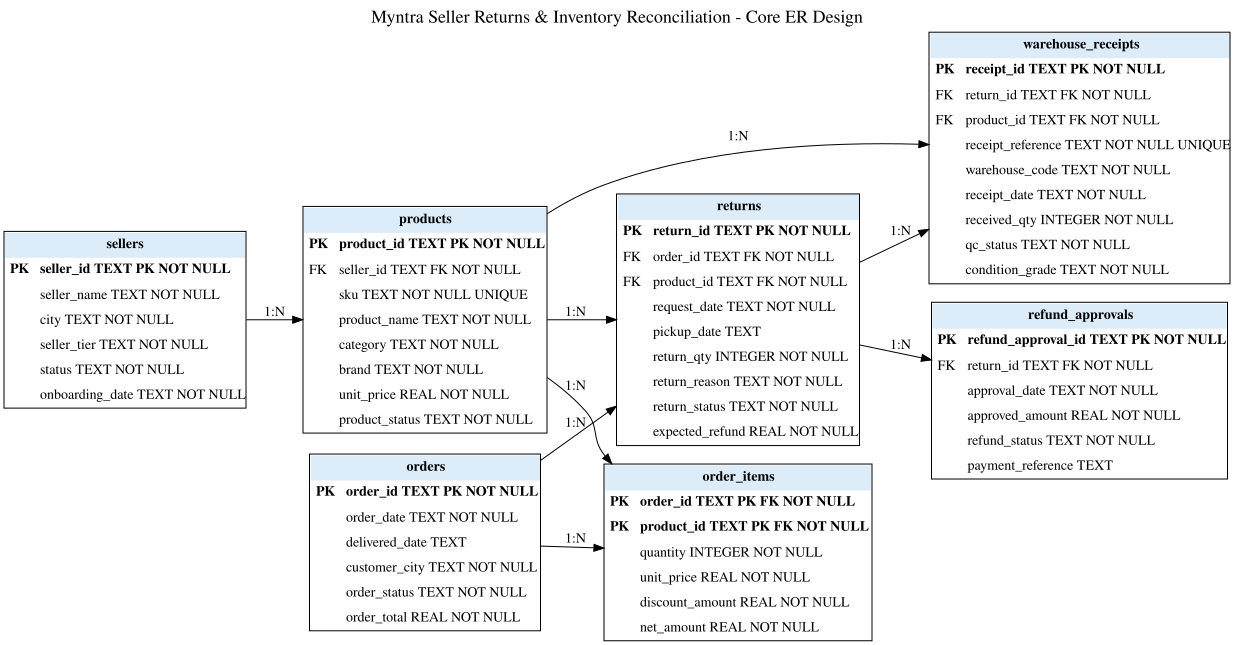

In [ ]:
# SQL DEVELOPER WORKSPACE - ER-1
# TODO: Add all required fields beneath each table key, including PK/FK/NOT NULL/UNIQUE markers.
developer_tables = {
    "sellers": ["seller_id TEXT PK NOT NULL",
                "seller_name TEXT NOT NULL",
                "city TEXT NOT NULL",
                "seller_tier TEXT NOT NULL",
                "status TEXT NOT NULL",
                "onboarding_date TEXT NOT NULL"],
    "products": ["product_id TEXT PK NOT NULL",
                 "seller_id TEXT FK NOT NULL",
                 "sku TEXT NOT NULL UNIQUE",
                 "product_name TEXT NOT NULL",
                 "category TEXT NOT NULL",
                 "brand TEXT NOT NULL",
                 "unit_price REAL NOT NULL",
                 "product_status TEXT NOT NULL"],
    "orders": ["order_id TEXT PK NOT NULL",
               "order_date TEXT NOT NULL",
               "delivered_date TEXT",
               "customer_city TEXT NOT NULL",
               "order_status TEXT NOT NULL",
               "order_total REAL NOT NULL"],
    "order_items": ["order_id TEXT PK FK NOT NULL",
                    "product_id TEXT PK FK NOT NULL",
                    "quantity INTEGER NOT NULL",
                    "unit_price REAL NOT NULL",
                    "discount_amount REAL NOT NULL",
                    "net_amount REAL NOT NULL"],
    "returns": ["return_id TEXT PK NOT NULL",
                "order_id TEXT FK NOT NULL",
                "product_id TEXT FK NOT NULL",
                 "request_date TEXT NOT NULL",
                  "pickup_date TEXT",
                "return_qty INTEGER NOT NULL",
                  "return_reason TEXT NOT NULL",
               "return_status TEXT NOT NULL",
               "expected_refund REAL NOT NULL"],
    "warehouse_receipts": ["receipt_id TEXT PK NOT NULL",
                         "return_id TEXT FK NOT NULL",
                           "product_id TEXT FK NOT NULL",
                          "receipt_reference TEXT NOT NULL UNIQUE",
                           "warehouse_code TEXT NOT NULL",
                             "receipt_date TEXT NOT NULL",
                            "received_qty INTEGER NOT NULL",
                              "qc_status TEXT NOT NULL",
                            "condition_grade TEXT NOT NULL"],
    "refund_approvals": ["refund_approval_id TEXT PK NOT NULL",
                        "return_id TEXT FK NOT NULL",
                        "approval_date TEXT NOT NULL",
                        "approved_amount REAL NOT NULL",
                        "refund_status TEXT NOT NULL",
                        "payment_reference TEXT"],
}

# TODO: Add all required parent/child relationships using (parent_table, parent_key, child_table, child_key, "1:N").
developer_relationships = [
    ('sellers', 'seller_id', 'products', 'seller_id', '1:N'),
    ('orders', 'order_id', 'order_items', 'order_id', '1:N'),
    ('products', 'product_id', 'order_items', 'product_id', '1:N'),
    ('orders', 'order_id', 'returns', 'order_id', '1:N'),
    ('products', 'product_id', 'returns', 'product_id', '1:N'),
    ('returns', 'return_id', 'warehouse_receipts', 'return_id', '1:N'),
    ('products', 'product_id', 'warehouse_receipts', 'product_id', '1:N'),
    ('returns', 'return_id', 'refund_approvals', 'return_id', '1:N')
]

er_diagram = validate_er_design(developer_tables, developer_relationships)

### Expected Output - ER-1

- Exactly **7** core tables.
- Composite primary key on `order_items(order_id, product_id)`.
- All required primary-key and foreign-key markers.
- Exactly **8** required relationships.
- A rendered connected ER diagram after the design passes validation.
- **Overall status: Passed** only when the complete design is correct.


# 3. API Operations

The internal API server is already running. Your responsibility is to consume it with `requests`; do not modify or rebuild the server. Each mutable activity resets its own practice return before execution so you can rerun the cell safely.


In [ ]:
# Prebuilt API activity reference — no edits required
api_activity_reference = pd.DataFrame([
    {"Activity": "API-Q1", "Method": "GET", "Purpose": "Filtered return retrieval"},
    {"Activity": "API-Q2", "Method": "POST", "Purpose": "Create a provided return record"},
    {"Activity": "API-Q3", "Method": "PUT", "Purpose": "Complete return-record replacement"},
    {"Activity": "API-Q4", "Method": "PATCH", "Purpose": "Partial return-status update"},
    {"Activity": "API-Q5", "Method": "GET → DELETE → GET", "Purpose": "Deletion verification"},
])
display(api_activity_reference)
print("API activity reference ready. Use timeout=10 for every request.")


,Activity,Method,Purpose
0,API-Q1,GET,Filtered return retrieval
1,API-Q2,POST,Create a provided return record
2,API-Q3,PUT,Complete return-record replacement
3,API-Q4,PATCH,Partial return-status update
4,API-Q5,GET → DELETE → GET,Deletion verification


API activity reference ready. Use timeout=10 for every request.


## API-Q1 - Filtered GET

**Business requirement - Returns Operations:** Fetch exactly five return records where `return_status = RECEIVED` and `return_reason = SIZE_FIT`.

**How to approach:** Use `requests.get` on `/returns` with `limit`, `return_status`, and `return_reason` query parameters.


In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q1
import requests


# TODO: Write requests.get(...) with limit=5, return_status="RECEIVED", return_reason="SIZE_FIT", and timeout=10.
# api_q1_response = requests.get(...)
query_params = {
    "limit": 5,
    "return_status": "RECEIVED",
    "return_reason": "SIZE_FIT"
}
api_q1_response = requests.get(API_BASE_URL + "/returns", params=query_params, timeout=10)


validate_api_q1(api_q1_response)


,return_id,order_id,product_id,request_date,pickup_date,return_qty,return_reason,return_status,expected_refund
0,RET00001,ORD001213,PRD0199,2026-07-26,2026-07-27,2,SIZE_FIT,RECEIVED,"1,168.20"
1,RET00002,ORD000510,PRD0100,2026-07-18,2026-07-20,1,SIZE_FIT,RECEIVED,"1,799.10"
2,RET00003,ORD001155,PRD0080,2026-07-28,2026-07-29,1,SIZE_FIT,RECEIVED,"2,849.25"
3,RET00004,ORD000408,PRD0074,2026-07-28,2026-07-31,1,SIZE_FIT,RECEIVED,"1,039.20"
4,RET00005,ORD001017,PRD0173,2026-07-31,2026-08-01,1,SIZE_FIT,RECEIVED,674.10


HTTP 200 | records=5 | filters valid=True
Overall status: Passed


### Expected Output - API-Q1

- HTTP status **200**
- Exactly **5** returned records
- Every record has `return_status = RECEIVED` and `return_reason = SIZE_FIT`
- Records are displayed as a DataFrame when present.

The activity validator must finish with **Overall status: Passed**.


## API-Q2 - Create a Return with POST

**Business requirement - Returns Operations:** Create the supplied return request as a new internal API record.

**How to approach:** The payload is already provided. Write only the `requests.post` call.


In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q2
remove_api_practice_record("RET_API_POST_001")
new_return_payload = {
    "return_id": "RET_API_POST_001",
    "order_id": "ORD000001",
    "product_id": "PRD0022",
    "request_date": "2026-08-01",
    "pickup_date": None,
    "return_qty": 1,
    "return_reason": "NOT_AS_EXPECTED",
    "return_status": "REQUESTED",
    "expected_refund": 1709.05,
}
api_q2_response = requests.post(API_BASE_URL + "/returns", json=new_return_payload, timeout=10)

# TODO: Write requests.post(...) to create the provided return payload with timeout=10.
# api_q2_response = requests.post(...)

validate_api_q2(api_q2_response, new_return_payload)


,return_id,order_id,product_id,request_date,pickup_date,return_qty,return_reason,return_status,expected_refund
0,RET_API_POST_001,ORD000001,PRD0022,2026-08-01,None,1,NOT_AS_EXPECTED,REQUESTED,"1,709.05"


HTTP 201 | return_id=RET_API_POST_001 | payload_match=True
Overall status: Passed


### Expected Output - API-Q2

- HTTP status **201**
- Created `return_id` = `RET_API_POST_001`
- Response payload exactly matches the provided record.

The activity validator must finish with **Overall status: Passed**.


## API-Q3 - Complete Replacement with PUT

**Business requirement - Returns Operations:** Completely replace a reset practice return with the supplied replacement record.

**How to approach:** The reset and full replacement payload are provided. Write only the `requests.put` call.


In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q3
reset_api_practice_record("RET_API_PUT_001")
replacement_payload = {
    "return_id": "RET_API_PUT_001",
    "order_id": "ORD000002",
    "product_id": "PRD0205",
    "request_date": "2026-08-02",
    "pickup_date": "2026-08-03",
    "return_qty": 1,
    "return_reason": "DAMAGED",
    "return_status": "PICKED_UP",
    "expected_refund": 1851.55,
}
api_q3_response = requests.put(API_BASE_URL + "/returns/RET_API_PUT_001", json=replacement_payload, timeout=10)

# TODO: Write requests.put(...) to replace the complete practice return with timeout=10.
# api_q3_response = requests.put(...)

validate_api_q3(api_q3_response, replacement_payload)


,return_id,order_id,product_id,request_date,pickup_date,return_qty,return_reason,return_status,expected_refund
0,RET_API_PUT_001,ORD000002,PRD0205,2026-08-02,2026-08-03,1,DAMAGED,PICKED_UP,"1,851.55"


HTTP 200 | complete_replacement=True | exact_fields=True
Overall status: Passed


### Expected Output - API-Q3

- HTTP status **200**
- Response contains every replacement field
- Response contains no unexpected retained fields
- `return_id` remains `RET_API_PUT_001`.

The activity validator must finish with **Overall status: Passed**.


## API-Q4 - Partial Update with PATCH

**Business requirement - Warehouse Coordination:** Update only the pickup-related fields of a reset practice return without altering the original order, product, reason, quantity, or refund value.

**How to approach:** The reset baseline and patch payload are provided. Write only the `requests.patch` call.


In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q4
api_q4_baseline = reset_api_practice_record("RET_API_PATCH_001")
patch_payload = {"return_status": "PICKED_UP", "pickup_date": "2026-08-02"}
api_q4_response = requests.patch(API_BASE_URL + "/returns/RET_API_PATCH_001", json=patch_payload, timeout=10)

# TODO: Write requests.patch(...) with the provided partial payload and timeout=10.
# api_q4_response = requests.patch(...)

validate_api_q4(api_q4_response, api_q4_baseline, patch_payload)


,return_id,order_id,product_id,request_date,pickup_date,return_qty,return_reason,return_status,expected_refund
0,RET_API_PATCH_001,ORD000003,PRD0235,2026-08-01,2026-08-02,1,QUALITY,PICKED_UP,"1,319.20"


HTTP 200 | targeted_changed=True | untargeted_unchanged=True
Overall status: Passed


### Expected Output - API-Q4

- HTTP status **200**
- `return_status` changes to `PICKED_UP`
- `pickup_date` changes to `2026-08-02`
- All fields not named in the patch remain unchanged.

The activity validator must finish with **Overall status: Passed**.


## API-Q5 - GET -> DELETE -> GET Verification

**Business requirement - Returns Operations:** Verify a controlled deletion by reading a reset practice return, deleting it, and confirming it can no longer be retrieved.

**How to approach:** Reset the record first, then perform GET, DELETE, and GET in that order.


In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q5
reset_api_practice_record("RET_API_DELETE_001")
api_q5_read_before = requests.get(API_BASE_URL + "/returns/RET_API_DELETE_001", timeout=10)
api_q5_delete = requests.delete(API_BASE_URL + "/returns/RET_API_DELETE_001", timeout=10)
api_q5_read_after = requests.get(API_BASE_URL + "/returns/RET_API_DELETE_001", timeout=10)

# TODO: Write GET -> DELETE -> GET requests for RET_API_DELETE_001, each with timeout=10.
# api_q5_read_before = requests.get(...)
# api_q5_delete = requests.delete(...)
# api_q5_read_after = requests.get(...)

validate_api_q5(api_q5_read_before, api_q5_delete, api_q5_read_after)


,return_id,order_id,product_id,request_date,pickup_date,return_qty,return_reason,return_status,expected_refund
0,RET_API_DELETE_001,ORD000004,PRD0143,2026-08-01,2026-08-02,1,NOT_AS_EXPECTED,PICKED_UP,"1,399.00"


Status sequence: [200, 200, 404] | expected [200, 200, 404]
Overall status: Passed


### Expected Output - API-Q5

- Exact HTTP sequence: **200 -> 200 -> 404**
- Initial record is readable
- Delete is confirmed
- Final GET proves the record is absent.

The activity validator must finish with **Overall status: Passed**.


# 4. SQL Developer Questions

All business analysis in this section must be completed in SQL. Pandas is used only to display and validate the resulting DataFrame. The deterministic Dataset lets each question use exact expected columns, row counts, and stable key checks.


In [ ]:
# Prebuilt database catalog — no edits required
schema_catalog = []
for table_name in ["sellers", "products", "orders", "order_items", "returns", "warehouse_receipts", "refund_approvals", "inventory_adjustment_ledger", "reconciliation_exceptions", "api_ingestion_runs"]:
    column_info = conn.execute(f"PRAGMA table_info({table_name})").fetchall()
    schema_catalog.append({"table_name": table_name, "column_count": len(column_info)})
schema_catalog_df = pd.DataFrame(schema_catalog)
display(schema_catalog_df)
print("Database catalog ready. Complete SQL requirements only in SQL DEVELOPER WORKSPACE cells.")


,table_name,column_count
0,sellers,6
1,products,8
2,orders,6
3,order_items,6
4,returns,9
5,warehouse_receipts,9
6,refund_approvals,6
7,inventory_adjustment_ledger,9
8,reconciliation_exceptions,11
9,api_ingestion_runs,8


Database catalog ready. Complete SQL requirements only in SQL DEVELOPER WORKSPACE cells.


In [ ]:
import pandas as pd
orders_schema = pd.read_sql_query("PRAGMA table_info(orders)", conn)
display(orders_schema)

,cid,name,type,notnull,dflt_value,pk
0,0,order_id,TEXT,1,None,1
1,1,order_date,TEXT,1,None,0
2,2,delivered_date,TEXT,0,None,0
3,3,customer_city,TEXT,1,None,0
4,4,order_status,TEXT,1,None,0
5,5,order_total,REAL,1,None,0


In [ ]:
import pandas as pd
orders_ddl_df = pd.read_sql_query("SELECT sql FROM sqlite_master WHERE type='table' AND name='orders';", conn)
pd.set_option('display.max_colwidth', None)
display(orders_ddl_df)

,sql
0,"CREATE TABLE orders (\n order_id TEXT PRIMARY KEY NOT NULL,\n order_date TEXT NOT NULL,\n delivered_date TEXT,\n customer_city TEXT NOT NULL,\n order_status TEXT NOT NULL CHECK (order_status IN ('DELIVERED','CANCELLED','IN_TRANSIT')),\n order_total REAL NOT NULL CHECK (order_total >= 0)\n)"


## 4A. SQL Foundations and Multiple Tables


### Q1 - Highest-Value Unresolved Return Cases

**Business requirement - Marketplace Returns Operations Lead:**  
Show the ten highest-value return cases that are still in an unresolved operational stage so the team can prioritize seller and warehouse follow-up.

**Tables to use:** `returns, products, sellers`

**How to approach**
1. Join each return to its product and seller.
2. Keep only unresolved return statuses.
3. Sort by expected refund exposure from highest to lowest and return the top ten.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q1
q1_sql = r"""
SELECT
    r.return_id,
    s.seller_name,
    p.product_name,
    r.expected_refund,
    r.return_status,
    r.return_reason,
    r.request_date
FROM returns r
JOIN products p ON r.product_id = p.product_id
JOIN sellers s ON p.seller_id = s.seller_id
WHERE r.return_status NOT IN ('CLOSED', 'REJECTED')
ORDER BY r.expected_refund DESC
LIMIT 10;
"""

q1 = run_developer_query("Q1", q1_sql)

,return_id,seller_name,product_name,expected_refund,return_status,return_reason,request_date
0,RET00409,Cedar Styles 16,Threadline Footwear Item 080,"5,698.50",QC_COMPLETED,SIZE_FIT,2026-07-25
1,RET00142,Loom Fashion 10,Viora Women Ethnic Item 048,"5,198.00",RECEIVED,SIZE_FIT,2026-07-18
2,RET00316,Peak Wardrobe 26,Nivara Footwear Item 126,"5,013.30",RECEIVED,QUALITY,2026-07-24
3,RET00140,Nova Collective 24,Zestique Women Ethnic Item 116,"4,318.20",PICKED_UP,NOT_AS_EXPECTED,2026-07-20
4,RET00083,Indigo Trends 38,Fable Footwear Item 186,"3,949.00",PICKED_UP,SIZE_FIT,2026-07-06
5,RET00090,Indigo Styles 28,Mirae Footwear Item 140,"3,949.00",RECEIVED,NOT_AS_EXPECTED,2026-07-23
6,RET00230,Loom Styles 34,Nivara Footwear Item 170,"3,749.00",QC_COMPLETED,QUALITY,2026-07-16
7,RET00295,Indigo Styles 28,Mirae Footwear Item 140,"3,554.10",PICKED_UP,QUALITY,2026-07-09
8,RET00164,Peak Collective 59,Nivara Footwear Item 294,"3,419.05",QC_COMPLETED,DAMAGED,2026-07-15
9,RET00271,Peak Retail 29,Northlane Footwear Item 144,"3,399.00",REQUESTED,QUALITY,2026-07-31


Column check: Passed
Row-count check: 10 / expected 10 - Passed
Stable key-result check: {'return_id': 'RET00409', 'expected_refund': np.float64(5698.5), 'return_status': 'QC_COMPLETED'} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q1

**Required columns:** `return_id | seller_name | product_name | expected_refund | return_status | return_reason | request_date`  
**Expected row count:** **10**  
**Stable first-row / key-result check:** `return_id` = `RET00409`, `expected_refund` = `5698.5`, `return_status` = `QC_COMPLETED`

**Hint:** Use INNER JOIN, WHERE, ORDER BY, and LIMIT.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q2 - Seller Return Volume and Refund Exposure

**Business requirement - Seller Operations Manager:**  
Identify sellers with both meaningful return volume and material refund exposure so operational review can focus on sellers driving the largest return workload.

**Tables to use:** `sellers, products, returns`

**How to approach**
1. Join sellers to products and returns.
2. Aggregate return count and expected refund value per seller.
3. Use HAVING to keep only sellers meeting both minimum thresholds.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q2
q2_sql = r"""
SELECT
    s.seller_id,
    s.seller_name,
    COUNT(r.return_id) AS return_count,
    SUM(r.expected_refund) AS refund_exposure
FROM sellers s
JOIN products p ON s.seller_id = p.seller_id
JOIN returns r ON p.product_id = r.product_id
GROUP BY s.seller_id, s.seller_name
HAVING return_count >= 5
ORDER BY refund_exposure DESC, s.seller_id ASC
LIMIT 47;
"""

q2 = run_developer_query("Q2", q2_sql)

,seller_id,seller_name,return_count,refund_exposure
0,SEL028,Indigo Styles 28,10,"25,971.00"
1,SEL016,Cedar Styles 16,9,"21,680.60"
2,SEL045,Nova Retail 45,9,"18,113.55"
3,SEL056,Coral Fashion 56,9,"17,209.40"
4,SEL006,Aster Studio 06,10,"16,631.30"
5,SEL017,Cedar Styles 17,11,"16,130.55"
6,SEL036,Velvet Apparel 36,9,"15,754.50"
7,SEL009,Indigo Apparel 09,9,"15,356.70"
8,SEL052,Nexa Collective 52,10,"15,090.70"
9,SEL015,Cedar Collective 15,12,"15,071.80"


Column check: Passed
Row-count check: 47 / expected 47 - Passed
Stable key-result check: {'seller_id': 'SEL028', 'return_count': 10, 'refund_exposure': np.float64(25971.0)} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q2

**Required columns:** `seller_id | seller_name | return_count | refund_exposure`  
**Expected row count:** **47**  
**Stable first-row / key-result check:** `seller_id` = `SEL028`, `return_count` = `10`, `refund_exposure` = `25971.0`

**Hint:** Use GROUP BY, COUNT, SUM, HAVING, and ORDER BY.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q3 - Return, Warehouse and Refund Reconciliation

**Business requirement - Returns Reconciliation Manager:**  
List the highest-value returns where the warehouse quantity or refund approval does not reconcile with the original return request.

**Tables to use:** `returns, warehouse_receipts, refund_approvals, products, sellers`

**How to approach**
1. Aggregate warehouse receipt quantities per return.
2. Aggregate approved/completed refund amounts per return.
3. LEFT JOIN both aggregates to returns and classify the mismatch with COALESCE and CASE.


In [ ]:

# SQL DEVELOPER WORKSPACE - Q3

q3_sql = r"""
WITH warehouse_agg AS (
    SELECT
        return_id,
        SUM(received_qty) AS received_qty
    FROM warehouse_receipts
    GROUP BY return_id
),

refund_agg AS (
    SELECT
        return_id,
        SUM(approved_amount) AS approved_amount
    FROM refund_approvals
    WHERE refund_status IN ('APPROVED', 'COMPLETED')
    GROUP BY return_id
),

reconciliation AS (
    SELECT
        r.return_id,
        s.seller_name,
        r.return_qty,
        COALESCE(w.received_qty, 0) AS received_qty,
        r.expected_refund,
        COALESCE(a.approved_amount, 0.0) AS approved_amount,

        CASE
            WHEN w.return_id IS NULL
                THEN 'RECEIPT_MISSING'

            WHEN r.return_qty <> COALESCE(w.received_qty, 0)
                THEN 'QTY_MISMATCH'

            WHEN a.return_id IS NULL
                THEN 'REFUND_MISSING'

            WHEN ABS(
                r.expected_refund -
                COALESCE(a.approved_amount, 0.0)
            ) > 1.0
                THEN 'AMT_MISMATCH'

            ELSE 'RECONCILED'
        END AS reconciliation_status

    FROM returns r

    INNER JOIN products p
        ON r.product_id = p.product_id

    INNER JOIN sellers s
        ON p.seller_id = s.seller_id

    LEFT JOIN warehouse_agg w
        ON r.return_id = w.return_id

    LEFT JOIN refund_agg a
        ON r.return_id = a.return_id
)

SELECT
    return_id,
    seller_name,
    return_qty,
    received_qty,
    expected_refund,
    approved_amount,
    reconciliation_status

FROM reconciliation

WHERE reconciliation_status <> 'RECONCILED'

ORDER BY
    expected_refund DESC,
    return_id ASC

LIMIT 20;
"""

q3 = run_developer_query("Q3", q3_sql)


,return_id,seller_name,return_qty,received_qty,expected_refund,approved_amount,reconciliation_status
0,RET00142,Loom Fashion 10,2,2,"5,198.00",0.00,REFUND_MISSING
1,RET00316,Peak Wardrobe 26,2,2,"5,013.30",0.00,REFUND_MISSING
2,RET00140,Nova Collective 24,2,0,"4,318.20",0.00,RECEIPT_MISSING
3,RET00083,Indigo Trends 38,1,0,"3,949.00",0.00,RECEIPT_MISSING
4,RET00090,Indigo Styles 28,1,1,"3,949.00",0.00,REFUND_MISSING
5,RET00230,Loom Styles 34,1,2,"3,749.00","3,749.00",QTY_MISMATCH
6,RET00247,Aster Studio 06,1,1,"3,561.55",0.00,REFUND_MISSING
7,RET00295,Indigo Styles 28,1,0,"3,554.10",0.00,RECEIPT_MISSING
8,RET00126,Coral Fashion 56,1,1,"3,399.00","3,299.00",AMT_MISMATCH
9,RET00271,Peak Retail 29,1,0,"3,399.00",0.00,RECEIPT_MISSING


Column check: Passed
Row-count check: 20 / expected 20 - Passed
Stable key-result check: {'return_id': 'RET00142', 'expected_refund': np.float64(5198.0), 'reconciliation_status': 'REFUND_MISSING'} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q3

**Required columns:** `return_id | seller_name | return_qty | received_qty | expected_refund | approved_amount | reconciliation_status`  
**Expected row count:** **20**  
**Stable first-row / key-result check:** `return_id` = `RET00142`, `expected_refund` = `5198.0`, `reconciliation_status` = `REFUND_MISSING`

**Hint:** Use standard CTEs, LEFT JOIN, COALESCE, CASE, aggregation, and an amount tolerance.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q4 - Picked-Up Returns with No Warehouse Receipt

**Business requirement - Warehouse Control Lead:**  
Find returns that were picked up more than three days ago but still have no warehouse receipt record.

**Tables to use:** `returns, warehouse_receipts, products, sellers`

**How to approach**
1. Join return cases to seller information through products.
2. LEFT JOIN warehouse receipts.
3. Keep rows where no receipt exists and the pickup age exceeds the SLA.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q4
q4_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
SELECT r.return_id, s.seller_id, s.seller_name, r.pickup_date, r.return_status, r.expected_refund
FROM returns r
LEFT JOIN warehouse_receipts w ON r.return_id = w.return_id
JOIN products p ON r.product_id = p.product_id
JOIN sellers s ON p.seller_id = s.seller_id
WHERE w.return_id IS NULL AND r.pickup_date IS NOT NULL AND (julianday('2026-08-03') - julianday(r.pickup_date)) > 3
ORDER BY r.pickup_date,r.return_id ;
"""

q4 = run_developer_query("Q4", q4_sql)


,return_id,seller_id,seller_name,pickup_date,return_status,expected_refund
0,RET00301,SEL059,Peak Collective 59,2026-07-08,PICKED_UP,"2,478.40"
1,RET00404,SEL036,Velvet Apparel 36,2026-07-08,PICKED_UP,899.25
2,RET00083,SEL038,Indigo Trends 38,2026-07-09,PICKED_UP,"3,949.00"
3,RET00107,SEL001,Aura Fashion 01,2026-07-09,PICKED_UP,"3,284.10"
4,RET00120,SEL050,Peak Collective 50,2026-07-10,PICKED_UP,"1,086.75"
...,...,...,...,...,...,...
61,RET00102,SEL048,Aster Wardrobe 48,2026-07-29,PICKED_UP,"1,761.75"
62,RET00204,SEL047,Indigo Styles 47,2026-07-29,CLOSED,799.00
63,RET00399,SEL017,Cedar Styles 17,2026-07-29,PICKED_UP,479.20
64,RET00044,SEL009,Indigo Apparel 09,2026-07-30,PICKED_UP,"2,184.05"


Column check: Passed
Row-count check: 66 / expected 66 - Passed
Stable key-result check: {'return_id': 'RET00301', 'pickup_date': '2026-07-08', 'return_status': 'PICKED_UP'} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q4

**Required columns:** `return_id | seller_id | seller_name | pickup_date | return_status | expected_refund`  
**Expected row count:** **66**  
**Stable first-row / key-result check:** `return_id` = `RET00301`, `pickup_date` = `2026-07-08`, `return_status` = `PICKED_UP`

**Hint:** Use LEFT JOIN, NULL anti-join logic, and julianday date calculations.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


## 4B. SQL Functions, Set Operations, Subqueries, and Standard CTEs


### Q5 - Sellers with Quality Failures and Open Exceptions

**Business requirement - Marketplace Quality Manager:**  
Identify sellers that appear in both the set of QC-failed returns and the set of sellers with open or investigating reconciliation exceptions.

**Tables to use:** `sellers, products, returns, warehouse_receipts, reconciliation_exceptions`

**How to approach**
1. Build one seller set from QC-failed warehouse receipts.
2. Build a second seller set from unresolved exceptions.
3. Return the intersection with seller name and city.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q5
q5_sql = r"""
SELECT s.seller_id, s.seller_name, s.city
FROM sellers s
WHERE s.seller_id IN (
    SELECT p.seller_id
    FROM warehouse_receipts wr
    JOIN returns  r ON r.return_id  = wr.return_id
    JOIN products p ON p.product_id = r.product_id
    WHERE wr.qc_status = 'QC_FAILED'
    INTERSECT
    SELECT seller_id
    FROM reconciliation_exceptions
    WHERE resolution_status IN ('OPEN', 'INVESTIGATING')
)
ORDER BY s.seller_id;
"""

q5 = run_developer_query("Q5", q5_sql)


,seller_id,seller_name,city
0,SEL002,Aster Apparel 02,Mumbai
1,SEL003,Coral Wardrobe 03,Delhi
2,SEL004,Aster Wardrobe 04,Hyderabad
3,SEL005,Cedar Studio 05,Chennai
4,SEL006,Aster Studio 06,Pune
5,SEL007,Mint Apparel 07,Kolkata
6,SEL008,Velvet Fashion 08,Ahmedabad
7,SEL010,Loom Fashion 10,Mumbai
8,SEL011,Nexa Retail 11,Delhi
9,SEL012,Velvet Fashion 12,Hyderabad


Column check: Passed
Row-count check: 52 / expected 52 - Passed
Stable key-result check: {'seller_id': 'SEL002', 'city': 'Mumbai'} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q5

**Required columns:** `seller_id | seller_name | city`  
**Expected row count:** **52**  
**Stable first-row / key-result check:** `seller_id` = `SEL002`, `city` = `Mumbai`

**Hint:** Use INTERSECT (or an equivalent set-operation pattern) and joins.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q6 - Seller Risk Summary

**Business requirement - Seller Risk Operations Lead:**  
Produce a compact seller risk view with standardized names, city codes, seller age, return workload, unresolved exception count, return value, and a business-readable risk band.

**Tables to use:** `sellers, products, returns, reconciliation_exceptions`

**How to approach**
1. Aggregate return workload and exception counts in standard CTEs.
2. Join the aggregates to sellers.
3. Use SQL functions to format and classify the output.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q6
q6_sql = r"""
WITH ret AS (
    SELECT p.seller_id,
           COUNT(*)               AS return_count,
           SUM(r.expected_refund) AS return_value
    FROM returns r
    JOIN products p ON p.product_id = r.product_id
    GROUP BY p.seller_id
),
exc AS (
    SELECT seller_id, COUNT(*) AS open_exception_count
    FROM reconciliation_exceptions
    WHERE resolution_status IN ('OPEN', 'INVESTIGATING')
    GROUP BY seller_id
)
SELECT
    s.seller_id,
    UPPER(s.seller_name)                                   AS seller_name_upper,
    SUBSTR(s.city, 1, 3)                                   AS city_code,
    CAST(julianday('2026-08-03') - julianday(s.onboarding_date) AS INTEGER) AS seller_age_days,
    COALESCE(ret.return_count, 0)                          AS return_count,
    COALESCE(exc.open_exception_count, 0)                  AS open_exception_count,
    COALESCE(ret.return_value, 0)                          AS return_value,
    CASE
        WHEN COALESCE(exc.open_exception_count, 0) >= 5 THEN 'HIGH'
        WHEN COALESCE(exc.open_exception_count, 0) >= 2 THEN 'MEDIUM'
        ELSE 'LOW'
    END                                                    AS risk_band
FROM sellers s
LEFT JOIN ret ON ret.seller_id = s.seller_id
LEFT JOIN exc ON exc.seller_id = s.seller_id
ORDER BY open_exception_count DESC, return_value DESC, s.seller_id
LIMIT 15;
"""

q6 = run_developer_query("Q6", q6_sql)


,seller_id,seller_name_upper,city_code,seller_age_days,return_count,open_exception_count,return_value,risk_band
0,SEL052,NEXA COLLECTIVE 52,Hyd,827,10,12,"15,090.70",HIGH
1,SEL049,URBAN STYLES 49,Ben,993,12,9,"15,059.50",HIGH
2,SEL056,CORAL FASHION 56,Ahm,770,9,8,"17,209.40",HIGH
3,SEL059,PEAK COLLECTIVE 59,Del,1303,9,8,"14,981.45",HIGH
4,SEL003,CORAL WARDROBE 03,Del,1213,9,8,"11,571.40",HIGH
5,SEL016,CEDAR STYLES 16,Ahm,712,9,7,"21,680.60",HIGH
6,SEL045,NOVA RETAIL 45,Che,782,9,7,"18,113.55",HIGH
7,SEL006,ASTER STUDIO 06,Pun,633,10,7,"16,631.30",HIGH
8,SEL017,CEDAR STYLES 17,Ben,1064,11,7,"16,130.55",HIGH
9,SEL036,VELVET APPAREL 36,Hyd,809,9,7,"15,754.50",HIGH


Column check: Passed
Row-count check: 15 / expected 15 - Passed
Stable key-result check: {'seller_id': 'SEL052', 'open_exception_count': 12, 'risk_band': 'HIGH'} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q6

**Required columns:** `seller_id | seller_name_upper | city_code | seller_age_days | return_count | open_exception_count | return_value | risk_band`  
**Expected row count:** **15**  
**Stable first-row / key-result check:** `seller_id` = `SEL052`, `open_exception_count` = `12`, `risk_band` = `HIGH`

**Hint:** Use UPPER, SUBSTR, julianday, CAST, COALESCE, CASE, and standard CTEs.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q7 - Sellers Above the Marketplace Average Return Rate

**Business requirement - Marketplace Performance Manager:**  
Find sellers whose item-level return rate is above the marketplace-wide average seller return rate.

**Tables to use:** `sellers, products, order_items, orders, returns`

**How to approach**
1. Calculate a return rate for every seller.
2. Use a scalar subquery to calculate the average seller return rate.
3. Return only sellers above that benchmark.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q7
q7_sql = r"""
WITH
seller_rates AS (
    SELECT s.seller_id, s.seller_name, s.city,
           ROUND(COUNT(DISTINCT r.return_id) * 100.0
                 / NULLIF(COUNT(DISTINCT oi.order_id || '|' || oi.product_id), 0), 2) AS return_rate_pct
    FROM sellers s
    JOIN products    p  ON p.seller_id  = s.seller_id
    JOIN order_items oi ON oi.product_id = p.product_id
    JOIN orders      o  ON o.order_id    = oi.order_id AND o.order_status = 'DELIVERED'
    LEFT JOIN returns r ON r.order_id = oi.order_id AND r.product_id = oi.product_id
    GROUP BY s.seller_id, s.seller_name, s.city
)
SELECT seller_id, seller_name, return_rate_pct
FROM seller_rates
WHERE return_rate_pct > (SELECT AVG(return_rate_pct) FROM seller_rates)
ORDER BY return_rate_pct DESC, seller_id;
"""

q7 = run_developer_query("Q7", q7_sql)


,seller_id,seller_name,return_rate_pct
0,SEL059,Peak Collective 59,34.62
1,SEL035,Cedar Wardrobe 35,33.33
2,SEL015,Cedar Collective 15,30.00
3,SEL056,Coral Fashion 56,30.00
4,SEL017,Cedar Styles 17,28.21
5,SEL052,Nexa Collective 52,27.78
6,SEL011,Nexa Retail 11,27.27
7,SEL028,Indigo Styles 28,27.03
8,SEL020,Loom Fashion 20,26.67
9,SEL045,Nova Retail 45,26.47


Column check: Passed
Row-count check: 30 / expected 30 - Passed
Stable key-result check: {'seller_id': 'SEL059', 'return_rate_pct': np.float64(34.62)} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q7

**Required columns:** `seller_id | seller_name | return_rate_pct`  
**Expected row count:** **30**  
**Stable first-row / key-result check:** `seller_id` = `SEL059`, `return_rate_pct` = `34.62`

**Hint:** Use a standard CTE or derived table plus a scalar subquery and NULLIF.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q8 - Restock Quantity Reconciliation

**Business requirement - Inventory Reconciliation Lead:**  
Compare sellable quantities received from returns with the restock quantities recorded in the inventory adjustment ledger, and show only products with a gap.

**Tables to use:** `warehouse_receipts, returns, products, inventory_adjustment_ledger`

**How to approach**
1. Build expected restock quantity from QC-passed sellable receipts.
2. Build actual restock quantity from the ledger.
3. Compare both aggregates and keep non-zero gaps.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q8
q8_sql = r"""
WITH expected AS (
    SELECT p.seller_id, r.product_id, SUM(wr.received_qty) AS expected_restock_qty
    FROM warehouse_receipts wr
    JOIN returns  r ON r.return_id  = wr.return_id
    JOIN products p ON p.product_id = r.product_id
    WHERE wr.qc_status = 'QC_PASSED' AND wr.condition_grade = 'SELLABLE'
    GROUP BY p.seller_id, r.product_id
),
actual AS (
    SELECT seller_id, product_id, SUM(quantity_change) AS actual_restock_qty
    FROM inventory_adjustment_ledger
    WHERE adjustment_type = 'RESTOCK'
    GROUP BY seller_id, product_id
)
SELECT
    e.seller_id,
    e.product_id,
    e.expected_restock_qty,
    COALESCE(a.actual_restock_qty, 0) AS actual_restock_qty,
    e.expected_restock_qty - COALESCE(a.actual_restock_qty, 0) AS qty_gap
FROM expected e
LEFT JOIN actual a ON a.seller_id = e.seller_id AND a.product_id = e.product_id
WHERE e.expected_restock_qty <> COALESCE(a.actual_restock_qty, 0)
ORDER BY qty_gap DESC, e.seller_id, e.product_id;
"""

q8 = run_developer_query("Q8", q8_sql)


,seller_id,product_id,expected_restock_qty,actual_restock_qty,qty_gap
0,SEL016,PRD0080,5,3,2
1,SEL018,PRD0090,2,0,2
2,SEL003,PRD0014,3,2,1
3,SEL018,PRD0087,1,0,1
4,SEL059,PRD0293,2,1,1


Column check: Passed
Row-count check: 5 / expected 5 - Passed
Stable key-result check: {'seller_id': 'SEL016', 'product_id': 'PRD0080', 'qty_gap': 2} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q8

**Required columns:** `seller_id | product_id | expected_restock_qty | actual_restock_qty | qty_gap`  
**Expected row count:** **5**  
**Stable first-row / key-result check:** `seller_id` = `SEL016`, `product_id` = `PRD0080`, `qty_gap` = `2`

**Hint:** Use multiple non-recursive CTEs, LEFT JOIN, COALESCE, and arithmetic.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


## 4C. Window Functions


### Q9 - Seller Return-Rate Rank within City

**Business requirement - Regional Seller Operations Manager:**  
Rank sellers by return rate within each seller city so regional teams can identify the highest-return sellers in their own market.

**Tables to use:** `sellers, products, order_items, orders, returns`

**How to approach**
1. Calculate seller-level return rate.
2. Partition the ranking by seller city.
3. Rank return rate from highest to lowest.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q9
q9_sql = r"""
WITH
seller_rates AS (
    SELECT s.seller_id, s.seller_name, s.city,
           ROUND(COUNT(DISTINCT r.return_id) * 100.0
                 / NULLIF(COUNT(DISTINCT oi.order_id || '|' || oi.product_id), 0), 2) AS return_rate_pct
    FROM sellers s
    JOIN products    p  ON p.seller_id  = s.seller_id
    JOIN order_items oi ON oi.product_id = p.product_id
    JOIN orders      o  ON o.order_id    = oi.order_id AND o.order_status = 'DELIVERED'
    LEFT JOIN returns r ON r.order_id = oi.order_id AND r.product_id = oi.product_id
    GROUP BY s.seller_id, s.seller_name, s.city
)
SELECT
    city, seller_id, seller_name, return_rate_pct,
    RANK() OVER (PARTITION BY city ORDER BY return_rate_pct DESC) AS city_return_rank
FROM seller_rates
ORDER BY city, city_return_rank, seller_id;
"""

q9 = run_developer_query("Q9", q9_sql)


,city,seller_id,seller_name,return_rate_pct,city_return_rank
0,Ahmedabad,SEL056,Coral Fashion 56,30.00,1
1,Ahmedabad,SEL048,Aster Wardrobe 48,25.00,2
2,Ahmedabad,SEL016,Cedar Styles 16,23.08,3
3,Ahmedabad,SEL024,Nova Collective 24,21.88,4
4,Ahmedabad,SEL008,Velvet Fashion 08,21.21,5
5,Ahmedabad,SEL032,Nova Retail 32,19.23,6
6,Ahmedabad,SEL040,Velvet Collective 40,17.65,7
7,Bengaluru,SEL017,Cedar Styles 17,28.21,1
8,Bengaluru,SEL049,Urban Styles 49,25.53,2
9,Bengaluru,SEL009,Indigo Apparel 09,23.68,3


Column check: Passed
Row-count check: 60 / expected 60 - Passed
Stable key-result check: {'city': 'Ahmedabad', 'seller_id': 'SEL056', 'city_return_rank': 1} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q9

**Required columns:** `city | seller_id | seller_name | return_rate_pct | city_return_rank`  
**Expected row count:** **60**  
**Stable first-row / key-result check:** `city` = `Ahmedabad`, `seller_id` = `SEL056`, `city_return_rank` = `1`

**Hint:** Use RANK() OVER(PARTITION BY ... ORDER BY ...).

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q10 - Daily Refund Exposure, Running Total and Moving Average

**Business requirement - Returns Planning Manager:**  
Show each July date with daily expected refund exposure, cumulative exposure, and a seven-day moving average for workload planning.

**Tables to use:** `returns`

**How to approach**
1. Aggregate refund exposure by return request date.
2. Join to the fixed July calendar used by this operating period.
3. Apply window frames for the running total and seven-day moving average.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q10
q10_sql = r"""
WITH RECURSIVE calendar(d) AS (
    SELECT '2026-07-01'
    UNION ALL
    SELECT date(d, '+1 day') FROM calendar WHERE d < '2026-07-31'
),
daily AS (
    SELECT request_date AS d, SUM(expected_refund) AS exposure
    FROM returns
    GROUP BY request_date
),
joined AS (
    SELECT c.d AS return_date, COALESCE(dl.exposure, 0) AS daily_refund_exposure
    FROM calendar c
    LEFT JOIN daily dl ON dl.d = c.d
)
SELECT
    return_date,
    ROUND(daily_refund_exposure, 2) AS daily_refund_exposure,
    ROUND(SUM(daily_refund_exposure) OVER (ORDER BY return_date
          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW), 2) AS running_refund_exposure,
    ROUND(AVG(daily_refund_exposure) OVER (ORDER BY return_date
          ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 2) AS seven_day_moving_avg
FROM joined
ORDER BY return_date;
"""

q10 = run_developer_query("Q10", q10_sql)


,return_date,daily_refund_exposure,running_refund_exposure,seven_day_moving_avg
0,2026-07-01,0.00,0.00,0.00
1,2026-07-02,0.00,0.00,0.00
2,2026-07-03,0.00,0.00,0.00
3,2026-07-04,0.00,0.00,0.00
4,2026-07-05,"2,478.40","2,478.40",495.68
5,2026-07-06,"7,650.70","10,129.10","1,688.18"
6,2026-07-07,"13,810.45","23,939.55","3,419.94"
7,2026-07-08,"9,811.60","33,751.15","4,821.59"
8,2026-07-09,"12,325.55","46,076.70","6,582.39"
9,2026-07-10,"15,857.05","61,933.75","8,847.68"


Column check: Passed
Row-count check: 31 / expected 31 - Passed
Stable key-result check: {'return_date': '2026-07-01', 'daily_refund_exposure': np.float64(0.0), 'running_refund_exposure': np.float64(0.0)} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q10

**Required columns:** `return_date | daily_refund_exposure | running_refund_exposure | seven_day_moving_avg`  
**Expected row count:** **31**  
**Stable first-row / key-result check:** `return_date` = `2026-07-01`, `daily_refund_exposure` = `0.0`, `running_refund_exposure` = `0.0`

**Hint:** Use SUM() OVER with an unbounded frame and AVG() OVER with ROWS BETWEEN 6 PRECEDING AND CURRENT ROW.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q11 - Day-over-Day Refund Exposure Change

**Business requirement - Marketplace Operations Manager:**  
Compare each active return day with the previous active return day and calculate the percentage change in expected refund exposure.

**Tables to use:** `returns`

**How to approach**
1. Aggregate expected refund exposure by date.
2. Use LAG to bring in the previous day value.
3. Calculate percentage change safely when the previous value is non-zero.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q11
q11_sql = r"""
WITH daily AS (
    SELECT request_date AS return_date, SUM(expected_refund) AS refund_exposure
    FROM returns
    GROUP BY request_date
),
lagged AS (
    SELECT return_date, refund_exposure,
           LAG(refund_exposure) OVER (ORDER BY return_date) AS previous_day_exposure
    FROM daily
)
SELECT
    return_date,
    refund_exposure,
    previous_day_exposure,
    CASE
        WHEN previous_day_exposure IS NULL OR previous_day_exposure = 0 THEN NULL
        ELSE ROUND((refund_exposure - previous_day_exposure) * 100.0 / previous_day_exposure, 2)
    END AS pct_change
FROM lagged
ORDER BY return_date;
"""

q11 = run_developer_query("Q11", q11_sql)


,return_date,refund_exposure,previous_day_exposure,pct_change
0,2026-07-05,"2,478.40",NaN,NaN
1,2026-07-06,"7,650.70","2,478.40",208.70
2,2026-07-07,"13,810.45","7,650.70",80.51
3,2026-07-08,"9,811.60","13,810.45",-28.96
4,2026-07-09,"12,325.55","9,811.60",25.62
5,2026-07-10,"15,857.05","12,325.55",28.65
6,2026-07-11,"10,594.80","15,857.05",-33.19
7,2026-07-12,"27,828.75","10,594.80",162.66
8,2026-07-13,"12,249.90","27,828.75",-55.98
9,2026-07-14,"18,016.40","12,249.90",47.07


Column check: Passed
Row-count check: 27 / expected 27 - Passed
Stable key-result check: {'return_date': '2026-07-05', 'refund_exposure': np.float64(2478.4), 'previous_day_exposure': None} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q11

**Required columns:** `return_date | refund_exposure | previous_day_exposure | pct_change`  
**Expected row count:** **27**  
**Stable first-row / key-result check:** `return_date` = `2026-07-05`, `refund_exposure` = `2478.4`, `previous_day_exposure` = `None`

**Hint:** Use LAG, CASE, NULL-safe arithmetic, and ROUND.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q12 - First and Latest Return per Seller

**Business requirement - Seller Operations Manager:**  
Show the first and latest return record for every seller with return activity so the team can understand when return issues began and how recently they occurred.

**Tables to use:** `returns, products, sellers`

**How to approach**
1. Rank returns in ascending and descending date order within each seller.
2. Use ROW_NUMBER for both directions.
3. Use conditional aggregation to bring first and latest values into one row per seller.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q12
q12_sql = r"""
WITH ranked AS (
    SELECT
        s.seller_id, s.seller_name, r.return_id, r.request_date,
        ROW_NUMBER() OVER (PARTITION BY s.seller_id ORDER BY r.request_date ASC,  r.return_id ASC)  AS rn_first,
        ROW_NUMBER() OVER (PARTITION BY s.seller_id ORDER BY r.request_date DESC, r.return_id DESC) AS rn_latest
    FROM returns r
    JOIN products p ON p.product_id = r.product_id
    JOIN sellers  s ON s.seller_id  = p.seller_id
)
SELECT
    seller_id,
    seller_name,
    MAX(CASE WHEN rn_first  = 1 THEN return_id    END) AS first_return_id,
    MAX(CASE WHEN rn_first  = 1 THEN request_date END) AS first_return_date,
    MAX(CASE WHEN rn_latest = 1 THEN return_id    END) AS latest_return_id,
    MAX(CASE WHEN rn_latest = 1 THEN request_date END) AS latest_return_date
FROM ranked
GROUP BY seller_id, seller_name
ORDER BY seller_id;
"""

q12 = run_developer_query("Q12", q12_sql)


,seller_id,seller_name,first_return_id,first_return_date,latest_return_id,latest_return_date
0,SEL001,Aura Fashion 01,RET00107,2026-07-07,RET00077,2026-07-29
1,SEL002,Aster Apparel 02,RET00229,2026-07-09,RET00345,2026-07-31
2,SEL003,Coral Wardrobe 03,RET00385,2026-07-14,RET00037,2026-07-31
3,SEL004,Aster Wardrobe 04,RET00127,2026-07-16,RET00352,2026-07-30
4,SEL005,Cedar Studio 05,RET00184,2026-07-13,RET00267,2026-07-31
5,SEL006,Aster Studio 06,RET00261,2026-07-11,RET00318,2026-07-31
6,SEL007,Mint Apparel 07,RET00165,2026-07-09,RET00095,2026-07-29
7,SEL008,Velvet Fashion 08,RET00249,2026-07-19,RET00337,2026-07-31
8,SEL009,Indigo Apparel 09,RET00070,2026-07-12,RET00326,2026-07-31
9,SEL010,Loom Fashion 10,RET00258,2026-07-08,RET00187,2026-07-26


Column check: Passed
Row-count check: 60 / expected 60 - Passed
Stable key-result check: {'seller_id': 'SEL001', 'first_return_id': 'RET00107', 'latest_return_id': 'RET00077'} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q12

**Required columns:** `seller_id | seller_name | first_return_id | first_return_date | latest_return_id | latest_return_date`  
**Expected row count:** **60**  
**Stable first-row / key-result check:** `seller_id` = `SEL001`, `first_return_id` = `RET00107`, `latest_return_id` = `RET00077`

**Hint:** Use ROW_NUMBER() twice and MAX(CASE WHEN ...).

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


### Q13 - Top Exception Ranks per City with Ties

**Business requirement - Regional Marketplace Control Manager:**  
Return sellers in the top three exception-count ranks within each city, preserving ties so regional teams do not lose equally ranked sellers.

**Tables to use:** `sellers, reconciliation_exceptions`

**How to approach**
1. Aggregate unresolved exception counts per seller.
2. Apply DENSE_RANK within city.
3. Keep ranks one through three and order for review.


In [ ]:
# SQL DEVELOPER WORKSPACE - Q13
q13_sql = r"""
WITH counts AS (
    SELECT s.city, s.seller_id, s.seller_name, COUNT(*) AS open_exception_count
    FROM sellers s
    JOIN reconciliation_exceptions e ON e.seller_id = s.seller_id
    WHERE e.resolution_status IN ('OPEN', 'INVESTIGATING')
    GROUP BY s.city, s.seller_id, s.seller_name
),
ranked AS (
    SELECT *, DENSE_RANK() OVER (PARTITION BY city ORDER BY open_exception_count DESC) AS exception_rank
    FROM counts
)
SELECT city, seller_id, seller_name, open_exception_count, exception_rank
FROM ranked
WHERE exception_rank <= 3
ORDER BY city, exception_rank, seller_id;
"""

q13 = run_developer_query("Q13", q13_sql)


,city,seller_id,seller_name,open_exception_count,exception_rank
0,Ahmedabad,SEL056,Coral Fashion 56,8,1
1,Ahmedabad,SEL016,Cedar Styles 16,7,2
2,Ahmedabad,SEL048,Aster Wardrobe 48,5,3
3,Bengaluru,SEL049,Urban Styles 49,9,1
4,Bengaluru,SEL017,Cedar Styles 17,7,2
5,Bengaluru,SEL041,Nova Styles 41,5,3
6,Bengaluru,SEL057,Nexa Collective 57,5,3
7,Chennai,SEL045,Nova Retail 45,7,1
8,Chennai,SEL021,Cedar Styles 21,6,2
9,Chennai,SEL005,Cedar Studio 05,5,3


Column check: Passed
Row-count check: 34 / expected 34 - Passed
Stable key-result check: {'city': 'Ahmedabad', 'seller_id': 'SEL056', 'exception_rank': 1} - Passed
Deterministic result check: Passed
Overall status: Passed


#### Expected Output - Q13

**Required columns:** `city | seller_id | seller_name | open_exception_count | exception_rank`  
**Expected row count:** **34**  
**Stable first-row / key-result check:** `city` = `Ahmedabad`, `seller_id` = `SEL056`, `exception_rank` = `1`

**Hint:** Use DENSE_RANK() OVER(PARTITION BY city ORDER BY ... DESC) and filter the ranked CTE.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


# 5. Transaction Management

These activities use the system-managed `inventory_adjustment_ledger`. Each cell clears only its own practice adjustment ID before the SQL script runs, so the activity can be safely repeated.


## T1 - Commit an Approved Inventory Correction

**Business requirement - Inventory Control Lead:** Add an approved manual stock correction of **+3 units** for product `PRD0001` owned by seller `SEL001`, and preserve it permanently.

Use adjustment ID `ADJ-DEVELOPER-COMMIT`, timestamp `2026-08-03 10:00:00`, adjustment type `MANUAL_CORRECTION`, approval status `APPROVED`, and reason `Approved cycle-count correction`.


In [ ]:
# SQL DEVELOPER WORKSPACE - T1
t1_sql = r"""
BEGIN;
INSERT INTO inventory_adjustment_ledger
    (adjustment_id, seller_id, product_id, return_id, adjustment_timestamp,
     adjustment_type, quantity_change, approval_status, reason)
VALUES
    ('ADJ-DEVELOPER-COMMIT', 'SEL001', 'PRD0001', NULL, '2026-08-03 10:00:00',
     'MANUAL_CORRECTION', 3, 'APPROVED', 'Approved cycle-count correction');
COMMIT;
"""

t1_result = run_transaction_activity("T1", t1_sql)


Transaction order: Passed
Required transaction values: Passed
Persisted row values: Passed
Actual row present: True
Expected row present: True
Overall status: Passed


### Expected Output - T1

- Transaction order and all required business values validate.
- `Actual row present: True`.
- The committed adjustment remains in `inventory_adjustment_ledger`.
- **Overall status: Passed**.


## T2 - Roll Back an Unapproved Inventory Correction

**Business requirement - Inventory Control Lead:** Test a temporary **-5 unit** adjustment for product `PRD0002` owned by seller `SEL001`, but do not allow the unapproved change to persist.

Use adjustment ID `ADJ-DEVELOPER-ROLLBACK`, timestamp `2026-08-03 11:00:00`, adjustment type `MANUAL_CORRECTION`, approval status `PENDING` for the temporary SQL row, and reason `Unapproved temporary stock correction`.


In [ ]:
# SQL DEVELOPER WORKSPACE - T2
t2_sql = r"""
BEGIN;
INSERT INTO inventory_adjustment_ledger
    (adjustment_id, seller_id, product_id, return_id, adjustment_timestamp,
     adjustment_type, quantity_change, approval_status, reason)
VALUES
    ('ADJ-DEVELOPER-ROLLBACK', 'SEL001', 'PRD0002', NULL, '2026-08-03 11:00:00',
     'MANUAL_CORRECTION', -5, 'PENDING', 'Unapproved temporary stock correction');
ROLLBACK;
"""

t2_result = run_transaction_activity("T2", t2_sql)


Transaction order: Passed
Required transaction values: Passed
Persisted row values: Passed
Actual row present: False
Expected row present: False
Overall status: Passed


### Expected Output - T2

- Transaction order and all required business values validate.
- `Actual row present: False`.
- The attempted row uses approval status `PENDING`, and the rolled-back adjustment does not remain in `inventory_adjustment_ledger`.
- **Overall status: Passed**.


# 6. Workflow Automation

The design represents a production-ready scheduling pattern without attempting to keep a persistent cron daemon alive in Colab. Cron expressions are validated here, but an external persistent scheduler would be required after the Colab runtime stops.


## AUTO-FLOW - Design the Daily Reconciliation Process

Write exactly seven ordered process steps covering scheduler trigger, internal API call, HTTP/schema validation, raw JSON storage, SQLite loading, SQL report generation, and logging/monitoring.


Step count: 7 / expected 7 - Passed
Required concepts and order: Passed
Overall status: Passed


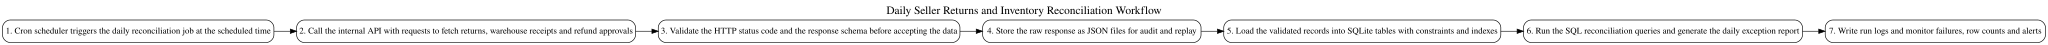

In [ ]:
# SQL DEVELOPER WORKSPACE - AUTO-FLOW
automation_steps = [
    "Cron scheduler triggers the daily reconciliation job at the scheduled time",
    "Call the internal API with requests to fetch returns, warehouse receipts and refund approvals",
    "Validate the HTTP status code and the response schema before accepting the data",
    "Store the raw response as JSON files for audit and replay",
    "Load the validated records into SQLite tables with constraints and indexes",
    "Run the SQL reconciliation queries and generate the daily exception report",
    "Write run logs and monitor failures, row counts and alerts",
]

automation_diagram = validate_sequence(
    "AUTO-FLOW", automation_steps, AUTO_GROUPS,
    "Daily Seller Returns and Inventory Reconciliation Workflow"
)


### Expected Output - AUTO-FLOW

- Exactly **7** steps.
- Required concepts appear in the correct order.
- A visible left-to-right workflow diagram renders after validation.
- **Overall status: Passed**.


## AUTO-REPORT - Daily Open-Exception Reconciliation Report

**Business requirement - Marketplace Operations Manager:**  
Generate the scheduled daily control report showing unresolved exception volume and expected-versus-actual values by exception type and severity.

**Tables to use:** `reconciliation_exceptions`

**How to approach**
1. Keep OPEN and INVESTIGATING cases.
2. Group by exception type and severity.
3. Return counts plus total expected and actual values ordered by operational severity.


In [ ]:
# SQL DEVELOPER WORKSPACE - AUTO-REPORT
auto_report_sql = r"""
SELECT
    exception_type,
    severity,
    COUNT(*) AS open_case_count,
    ROUND(SUM(COALESCE(expected_value, 0)), 2) AS total_expected_value,
    ROUND(SUM(COALESCE(actual_value, 0)), 2)   AS total_actual_value
FROM reconciliation_exceptions
WHERE resolution_status IN ('OPEN', 'INVESTIGATING')
GROUP BY exception_type, severity
ORDER BY CASE severity WHEN 'CRITICAL' THEN 1 WHEN 'HIGH' THEN 2 WHEN 'MEDIUM' THEN 3 ELSE 4 END,
         open_case_count DESC, exception_type;
"""

auto_report = run_developer_query("AUTO-REPORT", auto_report_sql)


,exception_type,severity,open_case_count,total_expected_value,total_actual_value
0,MISSING_WAREHOUSE_RECEIPT,CRITICAL,66,68.00,0.00
1,PENDING_REFUND_OVERDUE,CRITICAL,46,"73,307.15",0.00
2,DUPLICATE_REFUND_REFERENCE,CRITICAL,6,6.00,12.00
3,RECEIPT_QUANTITY_MISMATCH,HIGH,13,13.00,26.00
4,REFUND_AMOUNT_MISMATCH,HIGH,11,"17,236.90","16,386.90"
5,MISSING_INVENTORY_ADJUSTMENT,HIGH,5,7.00,0.00
6,QUALITY_REVIEW_OPEN,MEDIUM,106,106.00,0.00
7,LATE_WAREHOUSE_RECEIPT,MEDIUM,15,60.00,90.00


Column check: Passed
Row-count check: 8 / expected 8 - Passed
Stable key-result check: {'exception_type': 'MISSING_WAREHOUSE_RECEIPT', 'severity': 'CRITICAL', 'open_case_count': 66} - Passed
Deterministic result check: Passed
Overall status: Passed


### Expected Output - AUTO-REPORT

**Required columns:** `exception_type | severity | open_case_count | total_expected_value | total_actual_value`  
**Expected row count:** **8**  
**Stable first-row / key-result check:** `exception_type` = `MISSING_WAREHOUSE_RECEIPT`, `severity` = `CRITICAL`, `open_case_count` = `66`

**Hint:** Use WHERE, GROUP BY, COUNT, SUM, COALESCE, CASE in ORDER BY, and ROUND.

The validator checks exact columns, row count, the stable key result, deterministic row content, and final **Passed / Needs Review** status.


## AUTO-CRON - Write Cron Expressions

Write the exact five-field cron expressions for these four schedules:

1. Daily at 8 AM, 12 PM, and 4 PM.
2. Every weekday at 5 PM.
3. Every day at midnight.
4. Every Sunday at 2 AM.

These expressions are cron-ready, but the Colab runtime cannot act as a permanent scheduler after it stops.


In [ ]:
# SQL DEVELOPER WORKSPACE - AUTO-CRON
cron_answers = {
    "three_times_daily": "0 8,12,16 * * *",
    "weekday_5pm": "0 17 * * 1-5",
    "daily_midnight": "0 0 * * *",
    "sunday_2am": "0 2 * * 0",
}

cron_validation = validate_cron_answers(cron_answers)


,scenario,expression,five_fields,status
0,three_times_daily,"0 8,12,16 * * *",True,Passed
1,weekday_5pm,0 17 * * 1-5,True,Passed
2,daily_midnight,0 0 * * *,True,Passed
3,sunday_2am,0 2 * * 0,True,Passed


Overall status: Passed


### Expected Output - AUTO-CRON

A four-row validation table with all scenarios showing **Passed** and these exact expressions:

| Scenario | Expected expression |
|---|---|
| Daily at 8 AM, 12 PM, 4 PM | `0 8,12,16 * * *` |
| Weekdays at 5 PM | `0 17 * * 1-5` |
| Daily at midnight | `0 0 * * *` |
| Sunday at 2 AM | `0 2 * * 0` |


# 7. Engineering Practices

Represent professional engineering practice as ordered, validated workflows. No real repository creation or Git command execution is required.


## ENG-GIT - Git Collaboration Workflow

Write exactly eight steps: read the requirement/ticket, create a feature branch, write the SQL change, test and validate it, commit, push, open a pull request and complete review, then merge after approval.


Step count: 8 / expected 8 - Passed
Required concepts and order: Passed
Overall status: Passed


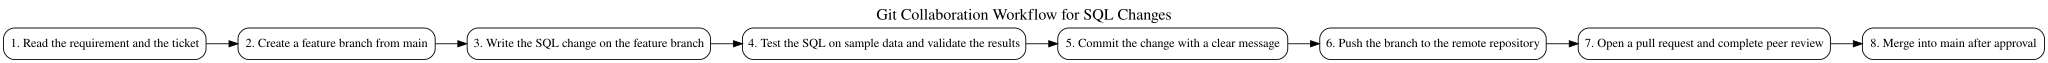

In [ ]:
# SQL DEVELOPER WORKSPACE - ENG-GIT
git_workflow_steps = [
    "Read the requirement and the ticket",
    "Create a feature branch from main",
    "Write the SQL change on the feature branch",
    "Test the SQL on sample data and validate the results",
    "Commit the change with a clear message",
    "Push the branch to the remote repository",
    "Open a pull request and complete peer review",
    "Merge into main after approval",
]

git_workflow_diagram = validate_sequence(
    "ENG-GIT", git_workflow_steps, GIT_GROUPS,
    "Git Collaboration Workflow for SQL Changes"
)


### Expected Output - ENG-GIT

- Exactly **8** steps in the required professional order.
- Required Git collaboration concepts validate.
- A visible workflow diagram renders.
- **Overall status: Passed**.


## ENG-CHANGE - Safe Database Change Workflow

Write exactly eight steps: understand the requirement, prepare backup and rollback plan, write the migration/SQL change, test in development, complete peer review, deploy the approved change, monitor logs/results, and roll back if deployment fails.


Step count: 8 / expected 8 - Passed
Required concepts and order: Passed
Overall status: Passed


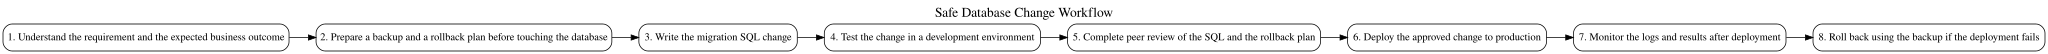

In [ ]:
# SQL DEVELOPER WORKSPACE - ENG-CHANGE
database_change_steps = [
    "Understand the requirement and the expected business outcome",
    "Prepare a backup and a rollback plan before touching the database",
    "Write the migration SQL change",
    "Test the change in a development environment",
    "Complete peer review of the SQL and the rollback plan",
    "Deploy the approved change to production",
    "Monitor the logs and results after deployment",
    "Roll back using the backup if the deployment fails",
]

database_change_diagram = validate_sequence(
    "ENG-CHANGE", database_change_steps, CHANGE_GROUPS,
    "Safe Database Change Workflow"
)


### Expected Output - ENG-CHANGE

- Exactly **8** steps in the required safe-change order.
- Backup, review, deployment, monitoring, and rollback concepts validate.
- A visible workflow diagram renders.
- **Overall status: Passed**.


# 8. Progress Check

Run the final cell to review all **26** activity IDs. The completed Instructor Solution must show all 26 as **Passed**.


In [ ]:
progress_dashboard = show_progress()


,activity_id,status
0,ER-1,Passed
1,API-Q1,Passed
2,API-Q2,Passed
3,API-Q3,Passed
4,API-Q4,Passed
5,API-Q5,Passed
6,Q1,Passed
7,Q2,Passed
8,Q3,Passed
9,Q4,Passed


,status,count
0,Passed,26


Passed activities: 26 / 26
